## Итоговый проект: гибридная системы рекомендаций книг с нейросетевыми моделями
###Выполнила: Чернова Ирина

**Цель проекта**
Разработать комплексную гибридную систему рекомендаций, объединяющую классические подходы с современными нейросетевыми архитектурами и оценить ее на разных сегментах пользователей.

**Данные**

**goodbooks-10k** (GitHub): 6M оценок, 10k книг, 10k пользователей, теги книг.

**Ключевые проблемы данных**

| Проблема | Значение | Что делаем |
|---|---|---|
| Разреженность | плотность ~1.1% (98.9% пустых ячеек) | sparse-матрицы, TF-IDF, ограничение K в KNN |
| Смещение популярности | медиана 111 оценок у юзера, 248 у книги, max 22806 | Baseline Popularity бязательная точка отсчёта |
| Холодный старт пользователя | после фильтра ≥10 взаимодействий реально «холодных» 0% | эмуляция через *truncated_histories* (1–4 и 5–20 книг) |
| Холодный старт книги | в датасете min 8 оценок у книги,т.е реального I-cold нет | эмуляция через *hidden_books*: 500 книг полностью удаляем из train |

**Структура работы**:

*Базовая часть:*
- **EDA + очистка:** распределение оценок, активность пользователей, разреженность.
- **Сплит leave-last-out:** train_full / val_full / test_full (последние 5 взаимодействий — val, ещё 5 — test).
- **Cold-start дизайн:** 4 среза val: regular (active), warm (5–20 книг), cold_users (1–4 книги), cold_items (500 скрытых книг).
- **Признаки:** temporal (recency_weight), user/item агрегаты, rating_centered, TF-IDF профили книг.
- **Базовые модели:** Random, Popularity, ContentBased, ItemKNN, SVD.
- **Гибрид:** взвешенный blend ItemKNN + ContentBased + Popularity + MMR (diversity). Веса подобраны на val_regular (grid search).

*Продвинутая часть:*
- **Two-Tower:** user tower (embedding + 7 признаков) + item tower (embedding + 5 признаков + TF-IDF-проекция), BCE loss, rating_centered bias. Two-Tower архитектура выбрана из-за сравнительной легкости интеграции в гибрид как источник кандидатов и быстрого инференса через предвычисленные эмбеддинги.
- **Интеграция в гибрид:** FinalHybridWithTT с w_tt=0.1 (TT слабее Hybrid).
- **Сквозной пайплайн:** run_pipeline (загрузка → предобработка → сплит → признаки → обучение гибрида → recommend() → оценка).

*Описаны выводы*

**Метрики**

Precision@K, Recall@K, nDCG@K (K = 5, 10, 20)


###**Этап 1. Окружение, загрузка датасета, короткий EDA и базовые признаки**

In [169]:
#настрйока окружения
import os, random, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import os
import gc
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import normalize
try:
    import surprise
except ImportError:
    !pip install -q scikit-surprise
    import surprise
from surprise import SVD, Dataset, Reader
import time

RANDOM_STATE = 42
DATA_DIR = "./goodbooks_data"
ARTIFACTS_DIR = "./artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

def set_seed(seed=RANDOM_STATE):
    random.seed(seed); np.random.seed(seed)
    import torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print(f"RANDOM_STATE = {RANDOM_STATE}")
print(f"DATA_DIR = {DATA_DIR}")

RANDOM_STATE = 42
DATA_DIR = ./goodbooks_data


In [208]:
#загрузка данных
os.makedirs(DATA_DIR, exist_ok=True)

#goodbooks-10k (актуальная версия v1.0, 6M оценок)
base_url = "https://github.com/zygmuntz/goodbooks-10k/releases/download/v1.0/"

files_to_download = ["ratings.zip", "books.zip", "tags.zip", "book_tags.zip"]

for fname in files_to_download:
    zip_path = os.path.join(DATA_DIR, fname)
    extract_marker = os.path.join(DATA_DIR, fname.replace(".zip", ".csv"))
    if not os.path.exists(extract_marker):
        urllib.request.urlretrieve(base_url + fname, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(DATA_DIR)

#данные
ratings   = pd.read_csv(os.path.join(DATA_DIR, "ratings.csv"))
books     = pd.read_csv(os.path.join(DATA_DIR, "books.csv"))
tags      = pd.read_csv(os.path.join(DATA_DIR, "tags.csv"))
book_tags = pd.read_csv(os.path.join(DATA_DIR, "book_tags.csv"))

print("Размеры данных:")
print(f"  ratings:   {ratings.shape}")
print(f"  books:     {books.shape}")
print(f"  tags:      {tags.shape}")
print(f"  book_tags: {book_tags.shape}")

print("\nПервые 3 строки ratings.csv:")
display(ratings.head(3))

print("\nПервые 3 строки books.csv:")
display(books.head(3))

Размеры данных:
  ratings:   (5976479, 3)
  books:     (10000, 23)
  tags:      (34252, 2)
  book_tags: (999912, 3)

Первые 3 строки ratings.csv:


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5



Первые 3 строки books.csv:


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...


Распределение оценок (доли):
rating
1    0.021
2    0.060
3    0.229
4    0.358
5    0.332
Name: proportion, dtype: float64
Средняя оценка: 3.920
Доля оценок >= 4: 0.690

Пользователей: 53,424
  Мин: 19 | Медиана: 111 | Макс: 200
Книг с оценками: 10,000
  Мин: 8 | Медиана: 248 | Макс: 22806


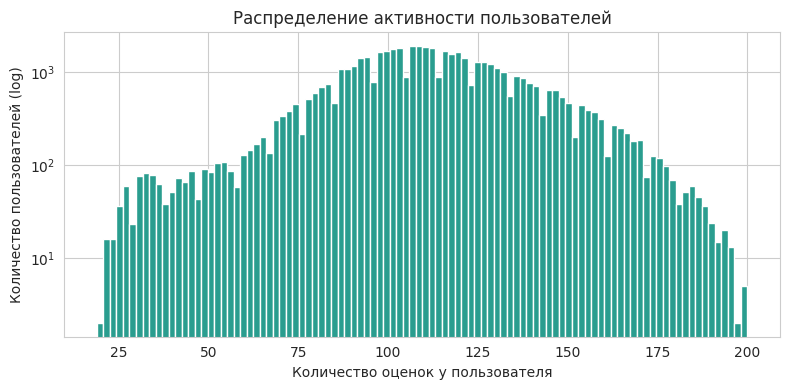


Пользователей с < 5 книг:  0 (0.00%)
Пользователей с < 10 книг: 0 (0.00%)

Разреженность: 98.8813% (плотность: 1.1187%)

После очистки: 5,976,479 взаимодействий
Доля релевантных (>=4): 0.690


In [209]:
#короткий EDA и очистка (датасет был заменен на его расширенную версию)
print("Распределение оценок (доли):")
print(ratings["rating"].value_counts(normalize=True).sort_index().round(3))
print(f"Средняя оценка: {ratings['rating'].mean():.3f}")
print(f"Доля оценок >= 4: {(ratings['rating'] >= 4).mean():.3f}")

user_activity = ratings.groupby("user_id").size()
book_popularity = ratings.groupby("book_id").size()
print(f"\nПользователей: {len(user_activity):,}")
print(f"  Мин: {user_activity.min()} | Медиана: {user_activity.median():.0f} | Макс: {user_activity.max()}")
print(f"Книг с оценками: {len(book_popularity):,}")
print(f"  Мин: {book_popularity.min()} | Медиана: {book_popularity.median():.0f} | Макс: {book_popularity.max()}")

#Распределение активности пользователей (график + пороги)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(user_activity, bins=100, color="#2a9d8f")
ax.set_yscale("log")
ax.set_title("Распределение активности пользователей")
ax.set_xlabel("Количество оценок у пользователя")
ax.set_ylabel("Количество пользователей (log)")
plt.tight_layout()
plt.show()
n_lt5 = (user_activity < 5).sum()
n_lt10 = (user_activity < 10).sum()
print(f"\nПользователей с < 5 книг:  {n_lt5:,} ({n_lt5/len(user_activity)*100:.2f}%)")
print(f"Пользователей с < 10 книг: {n_lt10:,} ({n_lt10/len(user_activity)*100:.2f}%)")

#Разреженность
n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
density = len(ratings) / (n_users * n_books)
print(f"\nРазреженность: {1 - density:.4%} (плотность: {density:.4%})")

#Очистка (без изменений)
books_clean = books[["book_id", "title", "average_rating", "ratings_count"]].copy()

if "original_order" not in ratings.columns:
    ratings = ratings.reset_index().rename(columns={"index": "original_order"})

ratings_clean = (ratings
    .groupby(["user_id", "book_id"])
    .agg(rating=("rating", "mean"), original_order=("original_order", "min"))
    .reset_index())

ratings_clean["is_relevant"] = (ratings_clean["rating"] >= 4).astype(int)

print(f"\nПосле очистки: {len(ratings_clean):,} взаимодействий")
print(f"Доля релевантных (>=4): {ratings_clean['is_relevant'].mean():.3f}")

In [210]:
#Базовые признаки (из ДЗ)
#TF-IDF профили книг (title + теги)
book_tags_named = book_tags.merge(tags, on="tag_id", how="left")

#Служебные теги
SERVICE_TAGS = {"to-read", "currently-reading", "read", "books-i-own", "owned", "owned-books",
                "wish-list", "to-buy", "library", "ebook", "audiobook", "kindle", "paperback",
                "hardcover", "favorites", "series", "book-club", "abandoned", "did-not-finish", "dnf"}
book_tags_clean = book_tags_named[~book_tags_named["tag_name"].isin(SERVICE_TAGS)]

book_id_map = books[["book_id", "goodreads_book_id"]].drop_duplicates(subset=["goodreads_book_id"], keep="first")
book_tags_mapped = (book_tags_clean
    .merge(book_id_map, on="goodreads_book_id", how="left")
    .loc[:, ["book_id", "tag_name"]]
    .dropna(subset=["book_id"])
    .assign(book_id=lambda d: d["book_id"].astype(int))
    .copy())
tags_per_book = (book_tags_mapped
    .dropna(subset=["book_id"])
    .groupby("book_id")["tag_name"]
    .apply(lambda s: " ".join(s.astype(str).str.replace("-", " ", regex=False)))
    .rename("tags_text")
    .reset_index())
book_profiles = books_clean[["book_id", "title"]].merge(tags_per_book, on="book_id", how="left").fillna({"tags_text": ""})
book_profiles["profile"] = (book_profiles["title"].fillna("") + " " + book_profiles["tags_text"]).str.strip()
book_profiles.loc[book_profiles["profile"] == "", "profile"] = "unknown book"
tfidf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(book_profiles["profile"]).astype(np.float32)
book_id_to_idx = {bid: i for i, bid in enumerate(book_profiles["book_id"])}
TFIDF_TOP_K = 50
tfidf_top_neighbors = {}
tfidf_matrix_T = tfidf_matrix.T.tocsr()
for bid, idx in book_id_to_idx.items():
    sims = (tfidf_matrix[idx] @ tfidf_matrix_T).toarray().ravel()
    sims[idx] = -np.inf
    top_idx = np.argpartition(-sims, TFIDF_TOP_K)[:TFIDF_TOP_K]
    top_idx = top_idx[np.argsort(-sims[top_idx])]
    tfidf_top_neighbors[bid] = (
        [int(book_profiles.iloc[i]["book_id"]) for i in top_idx],
        sims[top_idx].tolist())
_titles_by_id = book_profiles.set_index("book_id")["title"].to_dict()
def get_similar_books(book_id, N=5):
    if book_id not in tfidf_top_neighbors:
        return pd.DataFrame(columns=["book_id", "title", "similarity"])
    bids, sims = tfidf_top_neighbors[book_id]
    bids, sims = bids[:N], sims[:N]
    return pd.DataFrame({
        "book_id": bids,
        "title": [_titles_by_id.get(b, "") for b in bids],
        "similarity": sims})
print(f"TF-IDF: {tfidf_matrix.shape[0]} книг, {tfidf_matrix.shape[1]} признаков")

# Пример
sample_bid = int(book_profiles.iloc[10]["book_id"])
print(f"\nПохожие для book_id={sample_bid} ({book_profiles.iloc[10]['title']}):")
print(get_similar_books(sample_bid, N=3).to_string(index=False))

del books, book_tags, book_tags_named, book_tags_clean
gc.collect()

TF-IDF: 10000 книг, 30000 признаков

Похожие для book_id=11 (The Kite Runner):
 book_id                    title  similarity
      67 A Thousand Splendid Suns    0.314581
      64       My Sister's Keeper    0.243299
     378             The Namesake    0.231447


21703

##**Этап 2. Разбиение датасета на выборки, подготовка расширенных признаков и метрик**

In [211]:
#Leave-Last-Out Split
MIN_USER_INTERACTIONS = 10
user_counts = ratings_clean.groupby("user_id").size()
valid_users = user_counts[user_counts >= MIN_USER_INTERACTIONS].index
ratings_filtered = ratings_clean[ratings_clean["user_id"].isin(valid_users)].copy()
print(f"Пользователей всего: {ratings_clean['user_id'].nunique():,}")
print(f"Пользователей с >= {MIN_USER_INTERACTIONS} взаимодействиями: {len(valid_users):,}")
print(f"Взаимодействий после фильтра: {len(ratings_filtered):,} "
      f"({len(ratings_filtered)/len(ratings_clean)*100:.1f}% от исходных)")

ratings_filtered = ratings_filtered.sort_values(["user_id", "original_order"]).reset_index(drop=True)
ratings_filtered["rank"] = ratings_filtered.groupby("user_id").cumcount() + 1
ratings_filtered["n_user"] = ratings_filtered.groupby("user_id")["rank"].transform("max")
ratings_filtered["rank_from_end"] = ratings_filtered["n_user"] - ratings_filtered["rank"]

train_full = ratings_filtered[ratings_filtered["rank_from_end"] >= 10].copy()
val_full   = ratings_filtered[(ratings_filtered["rank_from_end"] >= 5) &
                              (ratings_filtered["rank_from_end"] < 10)].copy()
test_full  = ratings_filtered[ratings_filtered["rank_from_end"] < 5].copy()
print(f"\nРазмеры после split:")
print(f"  train_full: {len(train_full):,} ({len(train_full)/len(ratings_filtered)*100:.1f}%)")
print(f"  val_full:   {len(val_full):,} ({len(val_full)/len(ratings_filtered)*100:.1f}%)")
print(f"  test_full:  {len(test_full):,} ({len(test_full)/len(ratings_filtered)*100:.1f}%)")

assert (val_full.groupby("user_id").size() == 5).all(), "У пользователя больше 5 val"
assert (test_full.groupby("user_id").size() == 5).all(), "У пользователя больше 5 test"

train_pairs = set(zip(train_full["user_id"], train_full["book_id"]))
val_pairs   = set(zip(val_full["user_id"], val_full["book_id"]))
test_pairs  = set(zip(test_full["user_id"], test_full["book_id"]))
assert len(train_pairs & val_pairs) == 0, "Пересечение train_full/val_full"
assert len(train_pairs & test_pairs) == 0, "Пересечение train_full/test_full"
assert len(val_pairs & test_pairs) == 0, "Пересечение val_full/test_full"
print("Проверка: пересечений между train_full/val_full/test_full нет.")

#убираем служебные колонки
train_full = train_full.drop(columns=["rank", "n_user", "rank_from_end"], errors="ignore")
val_full   = val_full.drop(columns=["rank", "n_user", "rank_from_end"], errors="ignore")
test_full  = test_full.drop(columns=["rank", "n_user", "rank_from_end"], errors="ignore")


Пользователей всего: 53,424
Пользователей с >= 10 взаимодействиями: 53,424
Взаимодействий после фильтра: 5,976,479 (100.0% от исходных)

Размеры после split:
  train_full: 5,442,239 (91.1%)
  val_full:   267,120 (4.5%)
  test_full:  267,120 (4.5%)
Проверка: пересечений между train_full/val_full/test_full нет.


In [212]:
#Пулы cold/warm + truncated_histories + hidden_books (определяется ДО обучения моделей)
#анализ активности по train_full: кто может быть cold/warm
val_relevant = val_full[val_full["is_relevant"] == 1]
eval_users_pool = sorted(val_relevant["user_id"].unique())
train_user_counts = train_full.groupby("user_id").size().to_dict()

real_cold   = [u for u in eval_users_pool if train_user_counts.get(u, 0) < 5]
real_warm   = [u for u in eval_users_pool if 5 <= train_user_counts.get(u, 0) <= 20]
active_users = [u for u in eval_users_pool if train_user_counts.get(u, 0) > 20]

print(f"Юзеров с релевантной книгой в val: {len(eval_users_pool):,}")
print(f"  реальных cold (<5):    {len(real_cold):,}")
print(f"  реальных warm (5-20):  {len(real_warm):,}")
print(f"  active (>20):          {len(active_users):,}")

#пулы из active: 1000 cold + 1000 warm (не пересекаются)
rng_pool = np.random.default_rng(RANDOM_STATE)
N_SYNTHETIC = 1000
active_shuffled = rng_pool.choice(
    active_users, size=min(2 * N_SYNTHETIC, len(active_users)), replace=False)

cold_users_pool = set(active_shuffled[:N_SYNTHETIC])
warm_users_pool = set(active_shuffled[N_SYNTHETIC:2 * N_SYNTHETIC])

print(f"\nПулы (из active):")
print(f"  cold_users_pool: {len(cold_users_pool):,}")
print(f"  warm_users_pool: {len(warm_users_pool):,}")

rng_trunc = np.random.default_rng(RANDOM_STATE + 1)
truncated_histories = {}
for uid in cold_users_pool:
    user_hist = train_full[train_full["user_id"] == uid].sort_values("original_order")
    if len(user_hist) == 0:
        truncated_histories[uid] = set()
        continue
    k = int(rng_trunc.integers(1, min(4, len(user_hist)) + 1))
    truncated_histories[uid] = set(user_hist.head(k)["book_id"])
visible_cold_books = set().union(*truncated_histories.values()) if truncated_histories else set()
print(f"  visible_cold_books (книги в историях cold-юзеров): {len(visible_cold_books):,}")

rng_trunc_warm = np.random.default_rng(RANDOM_STATE + 3)
truncated_histories_warm = {}
for uid in warm_users_pool:
    user_hist = train_full[train_full["user_id"] == uid].sort_values("original_order")
    if len(user_hist) == 0:
        truncated_histories_warm[uid] = set()
        continue
    k = int(rng_trunc_warm.integers(5, min(20, len(user_hist)) + 1))
    truncated_histories_warm[uid] = set(user_hist.head(k)["book_id"])
visible_warm_books = set().union(*truncated_histories_warm.values()) if truncated_histories_warm else set()
print(f"  visible_warm_books (книги в историях warm-юзеров): {len(visible_warm_books):,}")

#hidden_books: 500 книг из val_full, кроме visible_cold_books
N_HIDDEN_BOOKS = 500
val_books = set(val_full["book_id"].unique())
candidate_books = sorted(val_books - visible_cold_books - visible_warm_books)
print(f"  кандидатов на скрытие: {len(candidate_books):,}")

if len(candidate_books) < N_HIDDEN_BOOKS:
    raise ValueError(
        f"Недостаточно книг для скрытия: {len(candidate_books)} < {N_HIDDEN_BOOKS}")

hidden_books = set(rng_pool.choice(candidate_books, size=N_HIDDEN_BOOKS, replace=False))
print(f"  hidden_books: {len(hidden_books):,}")

#инварианты
assert not (visible_cold_books & hidden_books), \
    "Конфликт: книга и в cold-истории, и в hidden_books"
assert len(cold_users_pool & warm_users_pool) == 0, \
    "cold_users_pool и warm_users_pool пересекаются"
assert not (visible_warm_books & hidden_books), \
    "Конфликт: книга и в warm-истории, и в hidden_books"
assert len(cold_users_pool & warm_users_pool) == 0, \
    "cold_users_pool и warm_users_pool пересекаются"

Юзеров с релевантной книгой в val: 51,443
  реальных cold (<5):    0
  реальных warm (5-20):  186
  active (>20):          51,257

Пулы (из active):
  cold_users_pool: 1,000
  warm_users_pool: 1,000
  visible_cold_books (книги в историях cold-юзеров): 1,337
  visible_warm_books (книги в историях warm-юзеров): 4,180
  кандидатов на скрытие: 5,418
  hidden_books: 500


In [213]:
#train_combined:
#(a) не-cold и не-warm: всё, кроме hidden_books
#(b) cold: только truncated_histories[uid]
#(c) warm: только truncated_histories_warm[uid]
#(d) фильтр: юзеры с < min_history_for_others взаимодействий удаляются

def build_combined_train(train_full, truncated_histories, hidden_books,
                         truncated_histories_warm=None,
                         min_history_for_others=3):
    cold_users = set(truncated_histories.keys())
    warm_users = set(truncated_histories_warm.keys()) if truncated_histories_warm else set()
    other_part = train_full[
        (~train_full["user_id"].isin(cold_users)) &
        (~train_full["user_id"].isin(warm_users)) &
        (~train_full["book_id"].isin(hidden_books))].copy()

    cold_pairs = pd.DataFrame(
        [(uid, bid) for uid, books in truncated_histories.items() for bid in books],
        columns=["user_id", "book_id"], dtype=np.int64)
    cold_part = train_full[
        train_full["user_id"].isin(cold_users)].merge(cold_pairs, on=["user_id", "book_id"], how="inner")
    cold_part = cold_part[~cold_part["book_id"].isin(hidden_books)].copy()

    if truncated_histories_warm:
        warm_pairs = pd.DataFrame(
            [(uid, bid) for uid, books in truncated_histories_warm.items() for bid in books],
            columns=["user_id", "book_id"], dtype=np.int64)
        warm_part = train_full[
            train_full["user_id"].isin(warm_users)].merge(warm_pairs, on=["user_id", "book_id"], how="inner")
        warm_part = warm_part[~warm_part["book_id"].isin(hidden_books)].copy()
    else:
        warm_part = train_full.iloc[0:0].copy()
    train_combined = pd.concat([other_part, cold_part, warm_part], ignore_index=True)
    del other_part, cold_part, warm_part
    if truncated_histories_warm:
        del cold_pairs, warm_pairs
    else:
        del cold_pairs
    if min_history_for_others > 0:
        counts = train_combined.groupby("user_id").size()
        keep_users = set(counts[counts >= min_history_for_others].index)
        train_combined = train_combined[train_combined["user_id"].isin(keep_users)].copy()
        del counts
    return train_combined

train_combined = build_combined_train(
    train_full, truncated_histories, hidden_books,
    truncated_histories_warm=truncated_histories_warm,
    min_history_for_others=3)

print(f"train_full:     {len(train_full):,}")
print(f"train_combined: {len(train_combined):,} "
      f"(удалено {len(train_full) - len(train_combined):,})")
print(f"Юзеров в train_combined: {train_combined['user_id'].nunique():,}")
print(f"Книг в train_combined:   {train_combined['book_id'].nunique():,}")

assert not (set(train_combined["book_id"]) & hidden_books), "hidden_books нашлись в train_combined"
assert len(train_combined) > 0, "train_combined пустой"

tc_grouped = train_combined.groupby("user_id")["book_id"].apply(set).to_dict()
for uid in truncated_histories:
    assert tc_grouped.get(uid, set()) <= truncated_histories[uid], f"У cold-юзера {uid} лишние книги в train_combined"
for uid in truncated_histories_warm:
    assert tc_grouped.get(uid, set()) <= truncated_histories_warm[uid], f"У warm-юзера {uid} лишние книги в train_combined"
print("hidden_books отсутствуют, у cold и warm только truncated-книги")

train_full:     5,442,239
train_combined: 5,149,910 (удалено 292,329)
Юзеров в train_combined: 52,928
Книг в train_combined:   9,500
hidden_books отсутствуют, у cold и warm только truncated-книги


In [214]:
#Четыре непересекающихся среза val: regular / cold_users / cold_items / warm
#Множество юзеров с hidden-книгой в val (кандидаты в cold_items)
val_cold_items = val_full[val_full["book_id"].isin(hidden_books)].copy()
val_cold_items_rel = val_cold_items[val_cold_items["is_relevant"] == 1]
cold_items_users = set(val_cold_items_rel["user_id"].unique())

#Классификация всех eval-юзеров на 4 непересекающихся пула
cold_users_set = set(cold_users_pool) & set(eval_users_pool)
cold_items_set = cold_items_users - cold_users_set
warm_users_set = (set(warm_users_pool) & set(eval_users_pool)- cold_users_set- cold_items_set)
regular_set = (set(eval_users_pool)- cold_users_set- cold_items_set- warm_users_set)

#Ограничиваем regular до 3000 (уже из очищенного пула)
rng_eval = np.random.default_rng(RANDOM_STATE + 2)
if len(regular_set) > 1500:
    regular_list = sorted(regular_set)
    pick = rng_eval.choice(len(regular_list), size=1500, replace=False)
    regular_set = {regular_list[i] for i in sorted(pick)}

#Cрезы из классифицированных множеств
eval_users_regular    = sorted(regular_set)
eval_users_cold       = sorted(cold_users_set)
eval_users_cold_items = sorted(cold_items_set)
eval_users_warm       = sorted(warm_users_set)

val_regular    = val_full[val_full["user_id"].isin(eval_users_regular)].copy()
val_cold_users = val_full[val_full["user_id"].isin(eval_users_cold)].copy()
val_cold_items = val_full[
    val_full["user_id"].isin(eval_users_cold_items) &
    val_full["book_id"].isin(hidden_books)].copy()
val_warm = val_full[val_full["user_id"].isin(eval_users_warm)].copy()

history_override_cold = {uid: truncated_histories.get(uid, set()) for uid in eval_users_cold}

print(f"val_regular:     юзеров в eval = {len(eval_users_regular):,}")
print(f"val_cold_users:  юзеров в eval = {len(eval_users_cold):,} (≤4 книги)")
print(f"val_cold_items:  юзеров в eval = {len(eval_users_cold_items):,} (hidden-книга в val)")
print(f"val_warm:        юзеров в eval = {len(eval_users_warm):,} (5–20 книг)")

#проверки
s_reg, s_cu, s_ci, s_warm = (set(eval_users_regular), set(eval_users_cold),
                              set(eval_users_cold_items), set(eval_users_warm))
assert not (s_reg & s_cu),  "val_regular ∩ val_cold_users ≠ ∅"
assert not (s_reg & s_ci),  "val_regular ∩ val_cold_items ≠ ∅"
assert not (s_reg & s_warm),"val_regular ∩ val_warm ≠ ∅"
assert not (s_cu & s_ci),   "val_cold_users ∩ val_cold_items ≠ ∅"
assert not (s_cu & s_warm), "val_cold_users ∩ val_warm ≠ ∅"
assert not (s_ci & s_warm), "val_cold_items ∩ val_warm ≠ ∅"
assert len(s_reg) > 0, "val_regular пустой"
assert len(s_cu) > 0,  "val_cold_users пустой"
assert len(s_ci) > 0,  "val_cold_items пустой"
assert len(s_warm) > 0, "val_warm пустой"
print(" Срезы не пересекаются, все непустые")

#проверка: val_cold_items содержит только hidden
assert set(val_cold_items["book_id"]) <= hidden_books, \
    "val_cold_items содержит не-hidden книги"
print(" val_cold_items содержит только hidden_books")

val_regular:     юзеров в eval = 1,500
val_cold_users:  юзеров в eval = 1,000 (≤4 книги)
val_cold_items:  юзеров в eval = 5,021 (hidden-книга в val)
val_warm:        юзеров в eval = 913 (5–20 книг)
 Срезы не пересекаются, все непустые
 val_cold_items содержит только hidden_books


In [215]:
#Временные признаки на train_combined
def add_temporal_features(df):
    df = df.sort_values(["user_id", "original_order"]).reset_index(drop=True)
    df["rank"] = df.groupby("user_id").cumcount() + 1
    df["n_user"] = df.groupby("user_id")["rank"].transform("max")
    df["rank_from_end"] = df["n_user"] - df["rank"]
    tau = 5.0
    df["recency_weight"] = np.exp(-df["rank_from_end"] / tau)
    return df

train_combined_t = add_temporal_features(train_combined)
print(f"train_combined_t: {train_combined_t.shape}")
print(f"  Колонки: {train_combined_t.columns.tolist()}")
user_avg_rating_map = train_combined_t.groupby("user_id")["rating"].mean()
train_combined_t["user_avg_rating"] = train_combined_t["user_id"].map(user_avg_rating_map)
train_combined_t["rating_centered"] = train_combined_t["rating"] - train_combined_t["user_avg_rating"]
print(f"rating_centered: mean={train_combined_t['rating_centered'].mean():.4f}, "
      f"std={train_combined_t['rating_centered'].std():.4f}")

min_rank_per_user = train_combined_t.groupby("user_id")["rank"].min()
assert (min_rank_per_user == 1).all(), "У части юзеров rank не начинается с 1"

rows_per_user = train_combined_t.groupby("user_id").size()
n_user_per_user = train_combined_t.groupby("user_id")["n_user"].first()
assert (rows_per_user == n_user_per_user).all(), "n_user не совпадает с числом строк"

assert train_combined_t["recency_weight"].between(0, 1, inclusive="right").all(), \
    "recency_weight вне (0, 1]"
assert (train_combined_t["recency_weight"] > 0).all(), "recency_weight == 0"

del ratings_clean, ratings_filtered, train_full, val_full, train_combined
gc.collect()

train_combined_t: (5149910, 9)
  Колонки: ['user_id', 'book_id', 'rating', 'original_order', 'is_relevant', 'rank', 'n_user', 'rank_from_end', 'recency_weight']
rating_centered: mean=-0.0000, std=0.8848


0

In [178]:
#агрегаты по train: user_feats_train / item_feats_train из train_combined_t
#признаки пользователей
user_feats_train = (train_combined_t
    .groupby("user_id").agg(
        user_n_ratings=("rating", "size"),
        user_avg_rating=("rating", "mean"),
        user_std_rating=("rating", "std"))
    .reset_index())
user_feats_train["user_std_rating"] = user_feats_train["user_std_rating"].fillna(0)
user_feats_train["user_log_n_ratings"] = np.log1p(user_feats_train["user_n_ratings"])

#temporal-агрегаты по high-rated книгам пользователя
high_rated = train_combined_t[train_combined_t["rating"] >= 4].copy()
high_rated["history_position"] = high_rated["rank"] / high_rated["n_user"]
agg_temporal = (high_rated
    .groupby("user_id").agg(user_avg_history_position=("history_position", "mean"),
         user_recency_bias=("recency_weight", "mean")).reset_index())
user_feats_train = user_feats_train.merge(agg_temporal, on="user_id", how="left")
user_feats_train["user_avg_history_position"] = user_feats_train["user_avg_history_position"].fillna(0.5)
user_feats_train["user_recency_bias"] = user_feats_train["user_recency_bias"].fillna(0.0)

#признаки книг
item_feats_train = (train_combined_t
    .groupby("book_id")
    .agg(item_n_ratings=("rating", "size"),
        item_avg_rating=("rating", "mean"),
        item_std_rating=("rating", "std")).reset_index())
item_feats_train["item_std_rating"] = item_feats_train["item_std_rating"].fillna(0)
item_feats_train["item_log_n_ratings"] = np.log1p(item_feats_train["item_n_ratings"])

#user_avg_rating_centered
high_rated_rc = train_combined_t[train_combined_t["rating"] >= 4].copy()
agg_user_rc = (high_rated_rc.groupby("user_id")
    .agg(user_avg_rating_centered=("rating_centered", "mean"))
    .reset_index())
user_feats_train = user_feats_train.merge(agg_user_rc, on="user_id", how="left")
user_feats_train["user_avg_rating_centered"] = user_feats_train["user_avg_rating_centered"].fillna(0.0)

#item_avg_rating_centered
agg_item_rc = (train_combined_t.groupby("book_id")
    .agg(item_avg_rating_centered=("rating_centered", "mean")).reset_index())
item_feats_train = item_feats_train.merge(agg_item_rc, on="book_id", how="left")
item_feats_train["item_avg_rating_centered"] = item_feats_train["item_avg_rating_centered"].fillna(0.0)
print(f"user_feats_train: {user_feats_train.shape}, колонки: {user_feats_train.columns.tolist()}")
print(f"item_feats_train: {item_feats_train.shape}, колонки: {item_feats_train.columns.tolist()}")

assert len(user_feats_train) == train_combined_t["user_id"].nunique(), "Число юзеров в user_feats_train не совпадает с train_combined_t"
assert len(item_feats_train) == train_combined_t["book_id"].nunique(), "Число книг в item_feats_train не совпадает с train_combined_t"
assert (user_feats_train["user_n_ratings"] > 0).all(), "user_n_ratings <= 0"
assert (item_feats_train["item_n_ratings"] > 0).all(), "item_n_ratings <= 0"
assert user_feats_train["user_avg_rating"].between(1, 5).all(), "user_avg_rating вне [1,5]"
assert item_feats_train["item_avg_rating"].between(1, 5).all(), "item_avg_rating вне [1,5]"
assert user_feats_train["user_avg_history_position"].between(0, 1).all(), "user_avg_history_position вне [0,1]"
assert user_feats_train["user_recency_bias"].between(0, 1).all(), "user_recency_bias вне [0,1]"

#статистика
print("\nuser_feats_train. describe:")
print(user_feats_train[["user_n_ratings", "user_avg_rating", "user_std_rating",
                        "user_avg_history_position", "user_recency_bias"]].describe().round(3).to_string())
print("\nitem_feats_train. describe:")
print(item_feats_train[["item_n_ratings", "item_avg_rating", "item_std_rating"]].describe().round(3).to_string())

user_feats_train: (52928, 8), колонки: ['user_id', 'user_n_ratings', 'user_avg_rating', 'user_std_rating', 'user_log_n_ratings', 'user_avg_history_position', 'user_recency_bias', 'user_avg_rating_centered']
item_feats_train: (9500, 6), колонки: ['book_id', 'item_n_ratings', 'item_avg_rating', 'item_std_rating', 'item_log_n_ratings', 'item_avg_rating_centered']

user_feats_train. describe:
       user_n_ratings  user_avg_rating  user_std_rating  user_avg_history_position  user_recency_bias
count       52928.000        52928.000        52928.000                  52928.000          52928.000
mean           97.300            3.934            0.858                      0.500              0.074
std            29.678            0.462            0.226                      0.047              0.095
min             3.000            1.000            0.000                      0.026              0.000
25%            82.000            3.632            0.731                      0.480              0.

In [179]:
#Перенос user_feats_train на val-срезы
USER_FEAT_COLS = ["user_n_ratings", "user_avg_rating", "user_std_rating",
                  "user_log_n_ratings", "user_avg_history_position",
                  "user_recency_bias", "user_avg_rating_centered"]

def attach_user_feats(df, user_feats, cols=USER_FEAT_COLS):
    out = df.merge(user_feats[["user_id"] + cols], on="user_id", how="left",
                   validate="many_to_one")
    out["user_n_ratings"] = out["user_n_ratings"].fillna(0).astype(int)
    out["user_log_n_ratings"] = out["user_log_n_ratings"].fillna(0.0)
    out["user_avg_rating"] = out["user_avg_rating"].fillna(user_feats["user_avg_rating"].mean())
    out["user_std_rating"] = out["user_std_rating"].fillna(0.0)
    out["user_avg_history_position"] = out["user_avg_history_position"].fillna(0.5)
    out["user_recency_bias"] = out["user_recency_bias"].fillna(0.0)
    out["user_avg_rating_centered"] = out["user_avg_rating_centered"].fillna(0.0)
    return out

n_reg, n_cu, n_ci = len(val_regular), len(val_cold_users), len(val_cold_items)
val_regular_fe    = attach_user_feats(val_regular,    user_feats_train)
val_cold_users_fe = attach_user_feats(val_cold_users, user_feats_train)
val_cold_items_fe = attach_user_feats(val_cold_items, user_feats_train)
val_warm_fe       = attach_user_feats(val_warm,       user_feats_train)
print(f"val_regular_fe:    {val_regular_fe.shape}")
print(f"val_cold_users_fe: {val_cold_users_fe.shape}")
print(f"val_cold_items_fe: {val_cold_items_fe.shape}")

assert len(val_regular_fe) == n_reg, "val_regular_fe: изменилось число строк"
assert len(val_cold_users_fe) == n_cu, "val_cold_users_fe: изменилось число строк"
assert len(val_cold_items_fe) == n_ci, "val_cold_items_fe: изменилось число строк"
assert val_regular_fe["user_avg_rating"].notna().all(), "val_regular_fe: NaN в user_avg_rating"
assert val_cold_users_fe["user_avg_rating"].notna().all(), "val_cold_users_fe: NaN в user_avg_rating"
assert val_cold_items_fe["user_avg_rating"].notna().all(), "val_cold_items_fe: NaN в user_avg_rating"
assert len(val_warm_fe) == len(val_warm), "val_warm_fe: изменилось число строк"
assert val_warm_fe["user_avg_rating"].notna().all(), "val_warm_fe: NaN в user_avg_rating"

cold_avg_n = val_cold_users_fe["user_n_ratings"].mean()
print(f"\nСреднее user_n_ratings у cold-юзеров: {cold_avg_n:.2f} "
      f"(ожидаемо 1–4, т.к. история урезана)")
warm_avg_n = val_warm_fe["user_n_ratings"].mean()
print(f"Среднее user_n_ratings у warm-юзеров: {warm_avg_n:.2f} (ожидаемо 5–20)")
assert 5 <= warm_avg_n <= 20, "У warm-юзеров user_n_ratings вне [5, 20]"
assert cold_avg_n <= 4.0, "У cold-юзеров user_n_ratings > 4, история не урезана?"


val_regular_fe:    (7500, 12)
val_cold_users_fe: (5000, 12)
val_cold_items_fe: (5510, 12)

Среднее user_n_ratings у cold-юзеров: 1.78 (ожидаемо 1–4, т.к. история урезана)
Среднее user_n_ratings у warm-юзеров: 12.51 (ожидаемо 5–20)


In [180]:
#rating_centered как фича для Two-Tower
def add_rating_centered_inplace(df):
    df["rating_centered"] = (df["rating"] - df["user_avg_rating"]).fillna(0.0)
    return df

val_regular_fe    = add_rating_centered_inplace(val_regular_fe)
val_cold_users_fe = add_rating_centered_inplace(val_cold_users_fe)
val_cold_items_fe = add_rating_centered_inplace(val_cold_items_fe)
val_warm_fe       = add_rating_centered_inplace(val_warm_fe)
print("статистика по train_combined_t:")
print(train_combined_t["rating_centered"].describe().round(3).to_string())
print("\nДоля NaN в rating_centered:")
print(f"  train_combined_t: {train_combined_t['rating_centered'].isna().mean():.4f}")
print(f"  val_regular_fe:   {val_regular_fe['rating_centered'].isna().mean():.4f}")
print(f"  val_cold_users_fe:{val_cold_users_fe['rating_centered'].isna().mean():.4f}")
print(f"  val_cold_items_fe:{val_cold_items_fe['rating_centered'].isna().mean():.4f}")

assert train_combined_t["rating_centered"].notna().all(), "NaN в train_combined_t"
assert val_regular_fe["rating_centered"].notna().all(), "NaN в val_regular_fe"
assert val_cold_users_fe["rating_centered"].notna().all(), "NaN в val_cold_users_fe"
assert val_cold_items_fe["rating_centered"].notna().all(), "NaN в val_cold_items_fe"
assert val_warm_fe["rating_centered"].notna().all(), "NaN в val_warm_fe"
assert train_combined_t["rating_centered"].between(-4, 4).all(), \
    "rating_centered вне [-4, 4] в train"
print(" rating_centered посчитан, NaN нет, значения в [-4, 4]")

статистика по train_combined_t:
count    5149910.000
mean          -0.000
std            0.885
min           -3.975
25%           -0.535
50%            0.102
75%            0.623
max            3.951

Доля NaN в rating_centered:
  train_combined_t: 0.0000
  val_regular_fe:   0.0000
  val_cold_users_fe:0.0000
  val_cold_items_fe:0.0000
 rating_centered посчитан, NaN нет, значения в [-4, 4]


In [181]:
#взвешенное по свежести косинусное сходство кандидата с историей юзера
def get_user_history_similarity_weighted(
        user_id, train_df, candidate_books,
        book_id_to_idx, tfidf_matrix, tfidf_matrix_T, tau=5.0):
    user_rows = train_df[train_df["user_id"] == user_id]
    valid_user_books = [b for b in user_rows["book_id"].tolist() if b in book_id_to_idx]
    if not valid_user_books:
        return {b: 0.0 for b in candidate_books}

    user_rows_valid = user_rows[user_rows["book_id"].isin(valid_user_books)]
    n_user = len(user_rows)
    ordered = user_rows["original_order"].to_numpy()
    valid_order = user_rows_valid["original_order"].to_numpy()
    ranks = np.searchsorted(np.sort(ordered), valid_order, side="left") + 1
    weights = np.exp(-(n_user - ranks) / tau).astype(np.float32)
    weights = weights / weights.sum()
    user_indices = np.array([book_id_to_idx[b] for b in valid_user_books], dtype=np.int64)
    user_vec = tfidf_matrix[user_indices].multiply(weights[:, None]).sum(axis=0)
    user_vec = csr_matrix(user_vec)
    all_scores = (user_vec @ tfidf_matrix_T).toarray().ravel()
    return {b: float(all_scores[book_id_to_idx[b]]) if b in book_id_to_idx else 0.0
            for b in candidate_books}

In [182]:
#быстрая проверка на одном юзере
sample_uid = train_combined_t["user_id"].iloc[0]
sample_candidates = list(book_id_to_idx.keys())[:100]
scores = get_user_history_similarity_weighted(
    sample_uid, train_combined_t, sample_candidates,
    book_id_to_idx, tfidf_matrix, tfidf_matrix_T)
print(f"Проверка: {len(scores)} скоров, "
      f"min={min(scores.values()):.4f}, max={max(scores.values()):.4f}")

Проверка: 100 скоров, min=0.0151, max=0.1227


In [183]:
#Метрики (Precision/Recall/nDCG@K) + evaluate()
train_grouped_global = (train_combined_t
    .groupby("user_id")["book_id"]
    .apply(set)
    .to_dict())
def precision_at_k(recommended, relevant, k):
    #доля релевантных в топ-K
    if k <= 0:
        return 0.0
    return len(set(recommended[:k]) & relevant) / k

def recall_at_k(recommended, relevant, k):
    #Доля найденных релевантных из всех релевантных
    if len(relevant) == 0:
        return 0.0
    return len(set(recommended[:k]) & relevant) / len(relevant)

def ndcg_at_k(recommended, relevant, k):
    #nDCG@K: DCG по фактическим позициям, IDCG длины k
    if k <= 0 or len(relevant) == 0:
        return 0.0
    rec_k = recommended[:k]
    rels = np.array([1.0 if b in relevant else 0.0 for b in rec_k])
    if rels.sum() == 0:
        return 0.0
    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    dcg = (rels * discounts[:len(rels)]).sum()
    ideal = np.zeros(k)
    ideal[:min(len(relevant), k)] = 1.0
    idcg = (ideal * discounts).sum()
    return dcg / idcg if idcg > 0 else 0.0

def evaluate(model, eval_users, train_grouped, eval_df, K_LIST=(5, 10, 20),
             history_override=None, return_per_user=False):
    #Оценка модели на срезе
    eval_relevant = (eval_df[eval_df["is_relevant"] == 1]
                     .groupby("user_id")["book_id"].apply(set).to_dict())
    results = {f"{m}@{k}": [] for k in K_LIST for m in ["Precision", "Recall", "nDCG"]}
    per_user = {} if return_per_user else None
    t0 = time.time()
    for uid in eval_users:
        if history_override is not None and uid in history_override:
            history = history_override[uid]
        else:
            history = train_grouped.get(uid, set())
        relevant = eval_relevant.get(uid, set())
        if not relevant:
            continue
        recs = model.recommend(uid, N=max(K_LIST), history=history)
        if return_per_user:
            per_user[uid] = {}
        for k in K_LIST:
            p = precision_at_k(recs, relevant, k)
            r = recall_at_k(recs, relevant, k)
            n = ndcg_at_k(recs, relevant, k)
            results[f"Precision@{k}"].append(p)
            results[f"Recall@{k}"].append(r)
            results[f"nDCG@{k}"].append(n)
            if return_per_user:
                per_user[uid].update({f"Precision@{k}": p, f"Recall@{k}": r, f"nDCG@{k}": n})
    summary = {m: round(float(np.mean(v)), 5) if v else 0.0 for m, v in results.items()}
    summary["Users"] = len(results["Precision@5"]) if K_LIST and "Precision@5" in results else 0
    summary["Time"] = round(time.time() - t0, 1)
    if return_per_user:
        return summary, per_user
    return summary

##**Этап 3. Обучение базовых моделей, сравнительная таблица**

In [184]:
#RandomRec + PopularityRec
class RandomRec:
    def __init__(self, all_books, seed=RANDOM_STATE):
        self.all_books = np.sort(np.array(sorted(all_books), dtype=np.int64))
        self.rng = np.random.default_rng(seed)

    def recommend(self, user_id, N=10, history=None):
        if history is None:
            history = set()
        mask = ~np.isin(self.all_books, np.fromiter(history, dtype=np.int64))
        candidates = self.all_books[mask]
        if len(candidates) == 0:
            return []
        k = min(N, len(candidates))
        return self.rng.choice(candidates, size=k, replace=False).tolist()

class PopularityRec:
    def __init__(self, min_ratings=30, m_prior=50):
        self.min_ratings = min_ratings
        self.m_prior = m_prior
        self.popular_sorted = None
        self.train_df = None
        self.global_mean = None

    def fit(self, train_df):
        self.train_df = train_df
        self.global_mean = float(train_df["rating"].mean())
        item_stats = (train_df
            .groupby("book_id")
            .agg(n_ratings=("rating", "size"),
                 avg_rating=("rating", "mean")).reset_index())
        item_stats["bayes_rating"] = (
            item_stats["n_ratings"] * item_stats["avg_rating"]
            + self.m_prior * self.global_mean) / (item_stats["n_ratings"] + self.m_prior)
        popular = item_stats[item_stats["n_ratings"] >= self.min_ratings]
        self.popular_sorted = (popular
            .sort_values("bayes_rating", ascending=False)
            .reset_index(drop=True))
        return self

    def recommend(self, user_id, N=10, history=None):
        if history is None:
            history = set(self.train_df.loc[
                self.train_df["user_id"] == user_id, "book_id"])
        candidates = self.popular_sorted[~self.popular_sorted["book_id"].isin(history)]
        if len(candidates) == 0:
            return self.popular_sorted.head(N)["book_id"].tolist()
        return candidates.head(N)["book_id"].tolist()
all_books = train_combined_t["book_id"].unique()

# Random
random_model = RandomRec(all_books)
sample_uid = int(train_combined_t["user_id"].iloc[0])
sample_hist = set(train_combined_t.loc[train_combined_t["user_id"] == sample_uid, "book_id"])
recs_random = random_model.recommend(sample_uid, N=10, history=sample_hist)
print(f"Random: {len(recs_random)} рекомендаций, пересечение с историей: {len(set(recs_random) & sample_hist)}")

# Popularity
pop_model = PopularityRec(min_ratings=30).fit(train_combined_t)
recs_pop = pop_model.recommend(sample_uid, N=10, history=sample_hist)
print(f"Popularity: {len(recs_pop)} рекомендаций, пересечение с историей: {len(set(recs_pop) & sample_hist)}")
print(f"  Топ-3: {recs_pop[:3]}")
print(f"  Всего популярных книг (n_ratings >= 30): {len(pop_model.popular_sorted):,}")

Random: 10 рекомендаций, пересечение с историей: 0
Popularity: 10 рекомендаций, пересечение с историей: 0
  Топ-3: [3628, 862, 1308]
  Всего популярных книг (n_ratings >= 30): 9,478


In [185]:
#ContentBasedRec с бустом seed-книг по топ-жанрам
def get_user_top_genres(user_id, train_df, book_tags, top_n=5):
    user_books = train_df.loc[train_df["user_id"] == user_id, "book_id"].tolist()
    if not user_books:
        return []
    user_tags = book_tags.loc[book_tags["book_id"].isin(user_books), "tag_name"].tolist()
    if not user_tags:
        return []
    return [tag for tag, _ in Counter(user_tags).most_common(top_n)]

class ContentBasedRec:
    def __init__(self, get_similar_fn, train_df, book_tags,
                 n_seed_books=5, genre_bonus=0.5):
        self.get_similar_fn = get_similar_fn
        self.train_df = train_df
        self.book_tags = book_tags
        self.n_seed_books = n_seed_books
        self.genre_bonus = genre_bonus
        self._user_ratings_by_user = {}
        self._train_df = train_df
        self._genres_cache = {}
        self._book_genres = (
            book_tags.groupby("book_id")["tag_name"]
            .apply(set).to_dict())

    def _get_user_genres(self, user_id):
        if user_id not in self._genres_cache:
            self._genres_cache[user_id] = set(
                get_user_top_genres(user_id, self.train_df, self.book_tags, top_n=5))
        return self._genres_cache[user_id]

    def _get_book_genres(self, book_id):
        return self._book_genres.get(book_id, set())

    def recommend(self, user_id, N=10, history=None):
        if history is None:
            history = set(self.train_df.loc[
                self.train_df["user_id"] == user_id, "book_id"])
        if len(history) == 0:
            return []
        user_genres = self._get_user_genres(user_id)
        seed_scored = []
        for bid in history:
            if user_id not in self._user_ratings_by_user:
                rows = self._train_df[self._train_df["user_id"] == user_id]
                self._user_ratings_by_user[user_id] = dict(zip(rows["book_id"], rows["rating"]))
            rating = self._user_ratings_by_user[user_id].get(bid, 0.0)
            overlap = len(self._get_book_genres(bid) & user_genres)
            seed_scored.append((bid, rating + self.genre_bonus * overlap))
        seed_scored.sort(key=lambda x: -x[1])
        seed_books = [bid for bid, _ in seed_scored[:self.n_seed_books]]
        scores = {}
        for bid in seed_books:
            try:
                similar = self.get_similar_fn(bid, N=N * 2)
                for _, row in similar.iterrows():
                    if row["book_id"] not in history:
                        scores[row["book_id"]] = (scores.get(row["book_id"], 0)
                                                  + row["similarity"])
            except (ValueError, KeyError):
                continue
        if not scores:
            return []
        return [bid for bid, _ in sorted(scores.items(), key=lambda x: -x[1])[:N]]

#модель для проверки работоспособности
cb = ContentBasedRec(
    get_similar_fn=get_similar_books,
    train_df=train_combined_t,
    book_tags=book_tags_mapped,   # плоский (book_id, tag_name)
    n_seed_books=5,
    genre_bonus=0.5)

#regular-юзер
sample_uid = int(train_combined_t["user_id"].iloc[0])
sample_hist = set(train_combined_t.loc[train_combined_t["user_id"] == sample_uid, "book_id"])
recs = cb.recommend(sample_uid, N=10, history=sample_hist)
print(f"ContentBased regular: {len(recs)} рекомендаций, "
      f"пересечение с историей: {len(set(recs) & sample_hist)}")

#cold-юзер
cold_uid = next(iter(truncated_histories))
cold_hist = truncated_histories[cold_uid]
recs_cold = cb.recommend(cold_uid, N=10, history=cold_hist)
print(f"ContentBased cold (история {len(cold_hist)} книг): {len(recs_cold)} рекомендаций")
print(f"_book_genres покрывает {len(cb._book_genres):,} книг")

ContentBased regular: 10 рекомендаций, пересечение с историей: 0
ContentBased cold (история 3 книг): 10 рекомендаций
_book_genres покрывает 10,000 книг


In [186]:
# ItemKNN + ItemKNNRec на train_combined_t
all_users = sorted(train_combined_t["user_id"].unique())
all_books_arr = sorted(train_combined_t["book_id"].unique())
u2i = {uid: i for i, uid in enumerate(all_users)}
i2i = {bid: i for i, bid in enumerate(all_books_arr)}
i2u = {i: uid for uid, i in u2i.items()}
i2b = {i: bid for bid, i in i2i.items()}
n_users = len(all_users)
n_books = len(all_books_arr)
rows = train_combined_t["user_id"].map(u2i).values
cols = train_combined_t["book_id"].map(i2i).values
vals = train_combined_t["rating"].values.astype(np.float32)
M_combined = csr_matrix((vals, (rows, cols)), shape=(n_users, n_books))
print(f"M_combined: {M_combined.shape}, nnz={M_combined.nnz:,}, "
      f"плотность={M_combined.nnz / (n_users * n_books) * 100:.4f}%")

class ItemKNN:
    #Item-Based CF через KNN по косинусной близости между книгами
    def __init__(self, k=100):
        self.k = k
        self.top_idx = None
        self.top_scores = None
        self.dead_items = None

    def fit(self, M, batch_size=500):
        Mn = normalize(M, axis=0).astype(np.float32)
        n_items = Mn.shape[1]
        self.top_idx = np.empty((n_items, self.k), dtype=np.int32)
        self.top_scores = np.empty((n_items, self.k), dtype=np.float32)
        col_norms = np.sqrt(np.asarray(Mn.multiply(Mn).sum(axis=0)).ravel())
        self.dead_items = set(np.where(col_norms == 0)[0].tolist())
        for start in range(0, n_items, batch_size):
            end = min(start + batch_size, n_items)
            batch = Mn[:, start:end].T
            sims = (batch @ Mn).toarray()
            for i in range(end - start):
                sims[i, start + i] = -np.inf
            top_k = np.argpartition(-sims, self.k, axis=1)[:, :self.k]
            self.top_idx[start:end] = top_k
            self.top_scores[start:end] = np.take_along_axis(sims, top_k, axis=1)
        for i in self.dead_items:
            self.top_idx[i] = -1
            self.top_scores[i] = -np.inf
        return self

    def recommend_batch(self, histories_idx, k=5):
        n = len(histories_idx)
        recs = np.full((n, k), -1, dtype=np.int64)
        for ui, idx in enumerate(histories_idx):
            if len(idx) == 0:
                continue
            idx = np.array([i for i in idx if i not in self.dead_items], dtype=np.int32)
            if len(idx) == 0:
                continue
            cand_idx = self.top_idx[idx].ravel()
            cand_scores = self.top_scores[idx].ravel()
            valid = cand_idx >= 0
            cand_idx, cand_scores = cand_idx[valid], cand_scores[valid]
            if len(cand_idx) == 0:
                continue
            uniq, inv = np.unique(cand_idx, return_inverse=True)
            agg = np.bincount(inv, weights=cand_scores).astype(np.float32)
            mask = ~np.isin(uniq, idx)
            uniq, agg = uniq[mask], agg[mask]
            if len(uniq) == 0:
                continue
            if len(uniq) > k:
                top_k = np.argpartition(-agg, k)[:k]
                top_k = top_k[np.argsort(-agg[top_k])]
            else:
                top_k = np.argsort(-agg)
            picked = uniq[top_k]
            if len(picked) < k:
                picked = np.concatenate([picked, np.full(k - len(picked), -1, dtype=np.int64)])
            recs[ui] = picked[:k]
        return recs

class ItemKNNRec:
    def __init__(self, ibcf_model, u2i, i2i, i2b, min_history=5):
        self.ibcf = ibcf_model
        self.u2i = u2i
        self.i2i = i2i
        self.i2b = i2b
        self.min_history = min_history

    def recommend(self, user_id, N=10, history=None):
        if history is None:
            history = set()
        hist_idx = np.array(
            [self.i2i[b] for b in history if b in self.i2i],
            dtype=np.int32)
        if len(hist_idx) < self.min_history:
            return []
        recs_idx = self.ibcf.recommend_batch([hist_idx], k=N)[0]
        return [int(self.i2b[i]) for i in recs_idx if i != -1]


#проверка работоспосбности
ibcf = ItemKNN(k=100).fit(M_combined, batch_size=500)
print(f"  top_idx.shape = {ibcf.top_idx.shape}")
print(f"  dead_items: {len(ibcf.dead_items):,} книг с нулевой нормой")

ibcf_wrapper = ItemKNNRec(ibcf, u2i, i2i, i2b, min_history=5)

assert ibcf.top_idx.shape == (n_books, 100), "top_idx неверной формы"
hidden_in_catalog = set(hidden_books) & set(all_books_arr)
assert len(hidden_in_catalog) == 0, "hidden_books попали в каталог ItemKNN"
print(" ItemKNN обучен, hidden_books отсутствуют в каталоге")

M_combined: (52928, 9500), nnz=5,149,910, плотность=1.0242%
  top_idx.shape = (9500, 100)
  dead_items: 0 книг с нулевой нормой
 ItemKNN обучен, hidden_books отсутствуют в каталоге


In [187]:
#SVDRec с fallback для unknown user
class SVDRec:
    def __init__(self, n_factors=10, n_epochs=20, lr_all=0.005, reg_all=0.1,
                 seed=RANDOM_STATE, fallback_rating=None):
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.lr_all = lr_all
        self.reg_all = reg_all
        self.seed = seed
        self.fallback_rating = fallback_rating
        self.model = None
        self.trainset = None
        self.all_books = None
        self.train_df = None
        self.global_mean = None
        self.known_users = set()

    def fit(self, train_df):
        self.train_df = train_df
        self.global_mean = float(train_df["rating"].mean())
        if self.fallback_rating is None:
            self.fallback_rating = self.global_mean
        self.all_books = np.array(sorted(train_df["book_id"].unique()))
        self.known_users = set(train_df["user_id"].unique())
        reader = Reader(rating_scale=(1, 5))
        data = Dataset.load_from_df(train_df[["user_id", "book_id", "rating"]], reader)
        self.trainset = data.build_full_trainset()
        self.model = SVD(
            n_factors=self.n_factors, n_epochs=self.n_epochs,
            lr_all=self.lr_all, reg_all=self.reg_all,
            random_state=self.seed)
        self.model.fit(self.trainset)
        return self

    def predict(self, user_id, book_id):
        if user_id not in self.known_users:
            return self.fallback_rating
        return self.model.predict(user_id, book_id).est

    def recommend(self, user_id, N=10, history=None):
        if history is None:
            history = set(self.train_df.loc[
                self.train_df["user_id"] == user_id, "book_id"])
        candidates = self.all_books[~np.isin(self.all_books, list(history))]
        if len(candidates) == 0:
            return []
        preds = np.array([self.predict(user_id, bid) for bid in candidates])
        n = min(N, len(candidates))
        top_idx = np.argpartition(-preds, n - 1)[:n]
        top_idx = top_idx[np.argsort(-preds[top_idx])]
        return candidates[top_idx].tolist()

svd_model = SVDRec(n_factors=32, n_epochs=40, lr_all=0.005, reg_all=0.1, seed=RANDOM_STATE).fit(train_combined_t)

print(f"SVD обучен: n_factors={svd_model.n_factors}, n_epochs={svd_model.n_epochs}")
print(f"  trainset: {svd_model.trainset.n_users:,} users, {svd_model.trainset.n_items:,} items")
print(f"  global_mean: {svd_model.global_mean:.4f}")
print(f"  known_users: {len(svd_model.known_users):,}")

assert svd_model.model is not None, "SVD не обучен"
assert svd_model.fallback_rating is not None, "fallback_rating не задан"
assert 1.0 <= svd_model.global_mean <= 5.0, "global_mean вне [1,5]"
assert svd_model.all_books.shape[0] == n_books, "all_books не совпадает с каталогом"
hidden_in_svd = set(hidden_books) & set(svd_model.all_books)
assert len(hidden_in_svd) == 0, "hidden_books попали в all_books SVD"
print(" SVD обучен, fallback для unknown user задан, hidden_books отсутствуют")

SVD обучен: n_factors=32, n_epochs=40
  trainset: 52,928 users, 9,500 items
  global_mean: 3.9204
  known_users: 52,928
 SVD обучен, fallback для unknown user задан, hidden_books отсутствуют


In [188]:
#Собирает 5 моделей в один словарь для evaluate_all_slices
def fit_all_models(train_df, all_books_arr, book_tags_mapped,
                   get_similar_books, ibcf, svd_model,
                   min_ratings=30, n_seed_books=5, genre_bonus=0.5):
    models = {
        "Random":       RandomRec(all_books_arr),
        "Popularity":   PopularityRec(min_ratings=min_ratings).fit(train_df),
        "ContentBased": ContentBasedRec(
                            get_similar_fn=get_similar_books,
                            train_df=train_df,
                            book_tags=book_tags_mapped,
                            n_seed_books=n_seed_books,
                            genre_bonus=genre_bonus),
        "ItemKNN":      ItemKNNRec(ibcf, u2i, i2i, i2b, min_history=5),
        "SVD":          svd_model}
    return models

models = fit_all_models(
    train_df=train_combined_t,
    all_books_arr=all_books_arr,
    book_tags_mapped=book_tags_mapped,
    get_similar_books=get_similar_books,
    ibcf=ibcf,
    svd_model=svd_model,
    min_ratings=30,
    n_seed_books=5,
    genre_bonus=0.5)

print(f"Собрано моделей: {len(models)}")
for name, m in models.items():
    print(f"  {name:>14}: {type(m).__name__}")

Собрано моделей: 5
          Random: RandomRec
      Popularity: PopularityRec
    ContentBased: ContentBasedRec
         ItemKNN: ItemKNNRec
             SVD: SVDRec


In [189]:
#Один цикл по models × 4 среза
def evaluate_all_slices(models, train_grouped, K_LIST=(5, 10, 20),
                        eval_users_regular=None, eval_users_cold=None,
                        eval_users_cold_items=None, eval_users_warm=None,
                        val_regular_fe=None, val_cold_users_fe=None,
                        val_cold_items_fe=None, val_warm_fe=None,
                        history_override_cold=None):
    def _eval_slice(eval_users, eval_df, history_override, slice_name):
        rows = {}
        for name, model in models.items():
            t0 = time.time()
            m = evaluate(model, eval_users, train_grouped, eval_df,
                         K_LIST=K_LIST,
                         history_override=history_override)
            m["Model"] = name
            rows[name] = m
            print(f"  [{slice_name}] {name:<14} "
                  f"P@10={m.get('Precision@10', 0):.5f}  "
                  f"nDCG@10={m.get('nDCG@10', 0):.5f}  "
                  f"({time.time() - t0:.1f}s)")
        df = pd.DataFrame(rows).T
        df.index.name = "Model"
        metric_cols = [c for c in df.columns
                       if any(c.startswith(p) for p in ("Precision", "Recall", "nDCG"))]
        df[metric_cols] = df[metric_cols].astype(float)
        return df

    print("REGULAR")
    regular_df = _eval_slice(eval_users_regular, val_regular_fe, None, "regular")
    print("\nWARM")
    warm_df = _eval_slice(eval_users_warm, val_warm_fe, None, "warm")
    print("\nCOLD USERS")
    cold_users_df = _eval_slice(eval_users_cold, val_cold_users_fe, history_override_cold, "cold_users")
    print("\nCOLD ITEMS")
    cold_items_df = _eval_slice(eval_users_cold_items, val_cold_items_fe, None, "cold_items")
    return regular_df, cold_users_df, cold_items_df, warm_df

t_start = time.time()
regular_df, cold_users_df, cold_items_df, warm_df = evaluate_all_slices(
    models=models,
    train_grouped=train_grouped_global,
    K_LIST=(5, 10, 20),
    eval_users_regular=eval_users_regular,
    eval_users_cold=eval_users_cold,
    eval_users_cold_items=eval_users_cold_items,
    eval_users_warm=eval_users_warm,
    val_regular_fe=val_regular_fe,
    val_cold_users_fe=val_cold_users_fe,
    val_cold_items_fe=val_cold_items_fe,
    val_warm_fe=val_warm_fe,
    history_override_cold=history_override_cold)
print(f"\nОбщее время: {time.time() - t_start:.1f}s")

REGULAR
  [regular] Random         P@10=0.00047  nDCG@10=0.00086  (0.2s)
  [regular] Popularity     P@10=0.00100  nDCG@10=0.00171  (0.9s)
  [regular] ContentBased   P@10=0.01453  nDCG@10=0.03148  (37.2s)
  [regular] ItemKNN        P@10=0.01893  nDCG@10=0.04043  (1.0s)
  [regular] SVD            P@10=0.00040  nDCG@10=0.00068  (62.8s)

WARM
  [warm] Random         P@10=0.00077  nDCG@10=0.00143  (0.1s)
  [warm] Popularity     P@10=0.00022  nDCG@10=0.00036  (0.5s)
  [warm] ContentBased   P@10=0.00504  nDCG@10=0.01155  (21.4s)
  [warm] ItemKNN        P@10=0.00701  nDCG@10=0.01324  (0.4s)
  [warm] SVD            P@10=0.00022  nDCG@10=0.00035  (37.5s)

COLD USERS
  [cold_users] Random         P@10=0.00000  nDCG@10=0.00000  (0.1s)
  [cold_users] Popularity     P@10=0.00080  nDCG@10=0.00161  (0.5s)
  [cold_users] ContentBased   P@10=0.00380  nDCG@10=0.00850  (15.8s)
  [cold_users] ItemKNN        P@10=0.00000  nDCG@10=0.00000  (0.0s)
  [cold_users] SVD            P@10=0.00080  nDCG@10=0.00127  (

##**Этап 4. Гибрид, его оптимизация и сравнительная таблица на разных сегментах пользователей**

In [190]:
#Гибрид
#Blend: w_ibcf * ItemKNN + w_content * ContentSim + w_pop * Popularity + MMR для diversity
class FinalHybridRec:
    def __init__(self, popularity_model, content_model, ibcf_model,
                 train_df, book_id_to_idx, tfidf_matrix, tfidf_matrix_T,
                 train_grouped=None, user_feats=None, item_feats=None,
                 min_history=5, w_ibcf=0.6, w_content=0.3, w_pop=0.1,
                 w_item_avg=0.05, content_top_k=1000, mmr_lambda=0.7):
        self.popularity = popularity_model
        self.content = content_model
        self.ibcf = ibcf_model
        self.train_df = train_df
        self.book_id_to_idx = book_id_to_idx
        self.tfidf_matrix = tfidf_matrix
        self.tfidf_matrix_T = tfidf_matrix_T
        self._train_grouped = train_grouped if train_grouped is not None else train_df.groupby("user_id")["book_id"].apply(set).to_dict()
        self.min_history = min_history
        self.w_ibcf = w_ibcf
        self.w_content = w_content
        self.w_pop = w_pop
        self.w_item_avg = w_item_avg
        self.content_top_k = content_top_k
        self.mmr_lambda = mmr_lambda
        self._global_mean = float(train_df["rating"].mean())
        if item_feats is not None:
            self._item_avg_rating = dict(zip(item_feats["book_id"], item_feats["item_avg_rating"]))
            self._item_std_rating = dict(zip(item_feats["book_id"], item_feats["item_std_rating"]))
        else:
            self._item_avg_rating = {}
            self._item_std_rating = {}
        if user_feats is not None:
            self._user_avg_rating = dict(zip(user_feats["user_id"], user_feats["user_avg_rating"]))
            self._user_recency_bias = dict(zip(user_feats["user_id"], user_feats["user_recency_bias"]))
        else:
            self._user_avg_rating = {}
            self._user_recency_bias = {}

    def _get_base_scores(self, user_id, history=None):
        if history is None:
            history = self._train_grouped.get(user_id, set())
        n_history = len(history)
        #cold: нет истории -> popularity (равномерные скоры)
        if n_history == 0:
            recs = self.popularity.recommend(user_id, N=10, history=history)
            if not recs:
                return {}
            return {bid: 1.0 / (rank + 1) for rank, bid in enumerate(recs)}
        #мало истории -> content, fallback popularity
        if n_history < self.min_history:
            recs = self.content.recommend(user_id, N=10, history=history)
            if not recs:
                recs = self.popularity.recommend(user_id, N=10, history=history)
            if not recs:
                return {}
            return {bid: 1.0 / (rank + 1) for rank, bid in enumerate(recs)}
        #активный юзер: blend
        recs_ibcf = self.ibcf.recommend(user_id, N=20, history=history)
        all_candidates = [b for b in self.book_id_to_idx.keys() if b not in history]
        content_scores_all = get_user_history_similarity_weighted(
                                  user_id, self.train_df, all_candidates,
                                  self.book_id_to_idx, self.tfidf_matrix, self.tfidf_matrix_T, tau=5.0)
        recs_pop = self.popularity.recommend(user_id, N=10, history=history)
        content_top = sorted(content_scores_all.items(), key=lambda x: -x[1])[:self.content_top_k]
        recs_content = [b for b, _ in content_top]
        candidates = list(dict.fromkeys(recs_ibcf + recs_content + recs_pop))
        candidates = [b for b in candidates if b not in history]
        if not candidates:
            return {}
        ibcf_scores = {bid: 1.0 / (rank + 1) for rank, bid in enumerate(recs_ibcf)}
        pop_scores = {bid: 1.0 / (rank + 1) for rank, bid in enumerate(recs_pop)}
        max_content = max(content_scores_all.values()) if content_scores_all else 1.0
        if max_content == 0:
            max_content = 1.0
        # --- расширенные признаки ---
        user_avg = self._user_avg_rating.get(user_id, self._global_mean)
        # нормируем в [-1, 1] относительно среднего
        user_avg_n = (user_avg - self._global_mean) / 2.0  # диапазон ~[-1, 1]
        # recency_bias: если юзер «свежий» (bias большой), усилить content
        recency_b = float(self._user_recency_bias.get(user_id, 0.0))
        content_mult = 1.0 + 0.2 * user_avg_n + 0.3 * recency_b  # ~[0.7, 1.5]

        final_scores = {}
        for bid in candidates:
            ibcf_s = ibcf_scores.get(bid, 0.0)
            content_s = content_scores_all.get(bid, 0.0) / max_content
            pop_s = pop_scores.get(bid, 0.0)
            item_avg = self._item_avg_rating.get(bid, self._global_mean)
            item_avg_n = (item_avg - self._global_mean) / 2.0
            item_std = self._item_std_rating.get(bid, 0.9)
            item_std_n = (item_std - 0.9) / 2.0

            final_scores[bid] = (
                self.w_ibcf * ibcf_s
                + self.w_content * content_s * content_mult
                + self.w_pop * pop_s
                + self.w_item_avg * item_avg_n
                - 0.02 * item_std_n)
        return final_scores

    def _mmr_rerank(self, candidates_scores, N):
        selected = []
        candidates = list(candidates_scores.keys())
        scores = dict(candidates_scores)
        while len(selected) < N and candidates:
            if selected:
                sel_idx = [self.book_id_to_idx[s] for s in selected
                           if s in self.book_id_to_idx]
                valid_cands, valid_idx = [], []
                for b in candidates:
                    if b in self.book_id_to_idx:
                        valid_cands.append(b)
                        valid_idx.append(self.book_id_to_idx[b])
                if sel_idx and valid_idx:
                    sims_sparse = (self.tfidf_matrix[valid_idx]
                                   @ self.tfidf_matrix[sel_idx].T)
                    sims_dense = sims_sparse.toarray()
                    max_sim_map = {b: float(sims_dense[i].max())
                                   for i, b in enumerate(valid_cands)}
                else:
                    max_sim_map = {}
            else:
                max_sim_map = {}

            best_mmr, best_bid = -float("inf"), None
            for bid in candidates:
                relevance = scores.get(bid, 0.0)
                diversity = max_sim_map.get(bid, 0.0)
                mmr = self.mmr_lambda * relevance - (1 - self.mmr_lambda) * diversity
                if mmr > best_mmr:
                    best_mmr, best_bid = mmr, bid
            if best_bid is None:
                break
            selected.append(best_bid)
            candidates.remove(best_bid)
        return selected

    def recommend(self, user_id, N=10, history=None):
        base_scores = self._get_base_scores(user_id, history)
        if not base_scores:
            return []
        sorted_candidates = sorted(base_scores.items(), key=lambda x: -x[1])
        top_scores = dict(sorted_candidates[:N * 3])
        return self._mmr_rerank(top_scores, N)

In [193]:
#создаём гибрид с дефолтными весами
hybrid_test = FinalHybridRec(
    popularity_model=models["Popularity"],
    content_model=models["ContentBased"],
    ibcf_model=models["ItemKNN"],
    train_df=train_combined_t,
    book_id_to_idx=book_id_to_idx,
    tfidf_matrix=tfidf_matrix,
    tfidf_matrix_T=tfidf_matrix_T,
    train_grouped=train_grouped_global,
    user_feats=user_feats_train,
    item_feats=item_feats_train,
    min_history=5,
    w_ibcf=0.6, w_content=0.3, w_pop=0.1,
    content_top_k=1000, mmr_lambda=0.7)

#regular-юзер
uid_reg = int(train_combined_t["user_id"].iloc[0])
hist_reg = set(train_combined_t.loc[train_combined_t["user_id"] == uid_reg, "book_id"])
recs_reg = hybrid_test.recommend(uid_reg, N=10, history=hist_reg)
print(f"Hybrid regular: {len(recs_reg)} рекомендаций, "
      f"пересечение: {len(set(recs_reg) & hist_reg)}")

#cold-юзер (1-4 книги)
uid_cold = next(iter(truncated_histories))
hist_cold = truncated_histories[uid_cold]
recs_cold = hybrid_test.recommend(uid_cold, N=10, history=hist_cold)
print(f"Hybrid cold: {len(recs_cold)} рекомендаций")

#юзер без истории (искусственно)
recs_empty = hybrid_test.recommend(uid_reg, N=10, history=set())
print(f"Hybrid без истории: {len(recs_empty)} рекомендаций (popularity)")

Hybrid regular: 10 рекомендаций, пересечение: 0
Hybrid cold: 10 рекомендаций
Hybrid без истории: 10 рекомендаций (popularity)


In [194]:
#Подбор весов гибрида на val_regular_fe (200 юзеров)
#подвыборка 200 regular-юзеров
rng_opt = np.random.default_rng(RANDOM_STATE + 10)
N_OPT = 200
if len(eval_users_regular) > N_OPT:
    opt_idx = rng_opt.choice(len(eval_users_regular), size=N_OPT, replace=False)
    eval_users_opt = [eval_users_regular[i] for i in sorted(opt_idx)]
else:
    eval_users_opt = eval_users_regular

w_ibcf_grid    = [0.6, 0.7]
w_content_grid = [0.2, 0.3]
w_pop_grid     = [0.0, 0.1]
mmr_lambda_grid = [0.8, 0.9]
results_grid = []
best_score = -1.0
best_params = None

t_start = time.time()
n_total = len(w_ibcf_grid) * len(w_content_grid) * len(w_pop_grid) * len(mmr_lambda_grid)
n_done = 0

for w_ibcf in w_ibcf_grid:
    for w_content in w_content_grid:
        for w_pop in w_pop_grid:
            if w_ibcf + w_content + w_pop > 1.0 + 1e-9:
                continue
            for mmr_lambda in mmr_lambda_grid:
                n_done += 1
                hybrid_try = FinalHybridRec(
                    popularity_model=models["Popularity"],
                    content_model=models["ContentBased"],
                    ibcf_model=models["ItemKNN"],
                    train_df=train_combined_t,
                    book_id_to_idx=book_id_to_idx,
                    tfidf_matrix=tfidf_matrix,
                    tfidf_matrix_T=tfidf_matrix_T,
                    train_grouped=train_grouped_global,
                    user_feats=user_feats_train,
                    item_feats=item_feats_train,
                    min_history=5,
                    w_ibcf=w_ibcf, w_content=w_content, w_pop=w_pop,
                    content_top_k=1000, mmr_lambda=mmr_lambda)

                m = evaluate(hybrid_try, eval_users_opt, train_grouped_global,
                             val_regular_fe, K_LIST=(10,), history_override=None)
                p10 = m["Precision@10"]
                results_grid.append({
                    "w_ibcf": w_ibcf, "w_content": w_content, "w_pop": w_pop,
                    "mmr_lambda": mmr_lambda, "Precision@10": p10})

                if p10 > best_score:
                    best_score = p10
                    best_params = (w_ibcf, w_content, w_pop, mmr_lambda)

print(f"Лучшие параметры: w_ibcf={best_params[0]}, w_content={best_params[1]}, "
      f"w_pop={best_params[2]}, mmr_lambda={best_params[3]}")
print(f"Precision@10 на подвыборке: {best_score:.5f}")

Лучшие параметры: w_ibcf=0.6, w_content=0.3, w_pop=0.0, mmr_lambda=0.9
Precision@10 на подвыборке: 0.05100


In [195]:
#Пересборка гибрида с лучшими весами
best_w_ibcf, best_w_content, best_w_pop, best_mmr_lambda = best_params
print(f"Создаём финальный гибрид с параметрами:")
print(f"  w_ibcf={best_w_ibcf}, w_content={best_w_content}, "
      f"w_pop={best_w_pop}, mmr_lambda={best_mmr_lambda}")

final_hybrid = FinalHybridRec(
    popularity_model=models["Popularity"],
    content_model=models["ContentBased"],
    ibcf_model=models["ItemKNN"],
    train_df=train_combined_t,
    book_id_to_idx=book_id_to_idx,
    tfidf_matrix=tfidf_matrix,
    tfidf_matrix_T=tfidf_matrix_T,
    train_grouped=train_grouped_global,
    user_feats=user_feats_train,
    item_feats=item_feats_train,
    min_history=5,
    w_ibcf=best_w_ibcf, w_content=best_w_content, w_pop=best_w_pop,
    content_top_k=1000, mmr_lambda=best_mmr_lambda)

models["Hybrid"] = final_hybrid

#быстрая проверка на одном юзере
sample_uid = int(train_combined_t["user_id"].iloc[0])
sample_hist = set(train_combined_t.loc[train_combined_t["user_id"] == sample_uid, "book_id"])
recs = final_hybrid.recommend(sample_uid, N=10, history=sample_hist)
print(f"\nПроверка: Hybrid regular -> {len(recs)} рекомендаций, "
      f"пересечение с историей: {len(set(recs) & sample_hist)}")

Создаём финальный гибрид с параметрами:
  w_ibcf=0.6, w_content=0.3, w_pop=0.0, mmr_lambda=0.9

Проверка: Hybrid regular -> 10 рекомендаций, пересечение с историей: 0


In [196]:
#Полная оценка 6 моделей
t_start = time.time()
regular_df, cold_users_df, cold_items_df, warm_df = evaluate_all_slices(
    models=models,
     train_grouped=train_grouped_global,
    K_LIST=(5, 10, 20),
    eval_users_regular=eval_users_regular,
    eval_users_cold=eval_users_cold,
    eval_users_cold_items=eval_users_cold_items,
    eval_users_warm=eval_users_warm,
    val_regular_fe=val_regular_fe,
    val_cold_users_fe=val_cold_users_fe,
    val_cold_items_fe=val_cold_items_fe,
    val_warm_fe=val_warm_fe,
    history_override_cold=history_override_cold)
print(f"\nОбщее время: {time.time() - t_start:.1f}s")

REGULAR
  [regular] Random         P@10=0.00040  nDCG@10=0.00065  (0.3s)
  [regular] Popularity     P@10=0.00100  nDCG@10=0.00171  (0.9s)
  [regular] ContentBased   P@10=0.01453  nDCG@10=0.03148  (13.9s)
  [regular] ItemKNN        P@10=0.01893  nDCG@10=0.04043  (1.1s)
  [regular] SVD            P@10=0.00040  nDCG@10=0.00068  (64.4s)
  [regular] Hybrid         P@10=0.04760  nDCG@10=0.08457  (55.2s)

WARM
  [warm] Random         P@10=0.00022  nDCG@10=0.00031  (0.1s)
  [warm] Popularity     P@10=0.00022  nDCG@10=0.00036  (0.5s)
  [warm] ContentBased   P@10=0.00504  nDCG@10=0.01155  (8.5s)
  [warm] ItemKNN        P@10=0.00701  nDCG@10=0.01324  (0.2s)
  [warm] SVD            P@10=0.00022  nDCG@10=0.00035  (36.1s)
  [warm] Hybrid         P@10=0.00602  nDCG@10=0.01230  (32.4s)

COLD USERS
  [cold_users] Random         P@10=0.00030  nDCG@10=0.00055  (0.1s)
  [cold_users] Popularity     P@10=0.00080  nDCG@10=0.00161  (0.5s)
  [cold_users] ContentBased   P@10=0.00380  nDCG@10=0.00850  (4.4s)
  [

## **Этап 5. Создание нейросетевой архитектуры и внедрение ее в гибрид**
### Two-Tower

In [197]:
#Подготовка данных для Two-Tower
torch.set_num_threads(os.cpu_count())
if hasattr(torch, "set_float32_matmul_precision"):
    torch.set_float32_matmul_precision("high")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

#маппинги по train_combined_t
user_ids = sorted(train_combined_t["user_id"].unique())
book_ids = sorted(train_combined_t["book_id"].unique())
u2i_tt = {uid: i for i, uid in enumerate(user_ids)}
i2i_tt = {bid: i for i, bid in enumerate(book_ids)}
i2b_tt = {i: bid for bid, i in i2i_tt.items()}
n_users_tt = len(user_ids)
n_books_tt = len(book_ids)

print(f"Two-Tower: {n_users_tt:,} users, {n_books_tt:,} books")
assert len(set(hidden_books) & set(book_ids)) == 0, "hidden_books попали в каталог TT"

#user_feats_tt
user_feat_cols = ["user_n_ratings", "user_avg_rating", "user_std_rating",
                  "user_log_n_ratings", "user_avg_history_position",
                  "user_recency_bias", "user_avg_rating_centered"]
user_feats_tt = (user_feats_train
    .set_index("user_id")[user_feat_cols]
    .reindex(user_ids)
    .fillna(0.0)
    .values.astype(np.float32))

#item_feats_tt
item_feat_cols = ["item_n_ratings", "item_avg_rating", "item_std_rating",
                  "item_log_n_ratings", "item_avg_rating_centered"]
item_feats_tt = (item_feats_train
    .set_index("book_id")[item_feat_cols]
    .reindex(book_ids)
    .fillna(0.0)
    .values.astype(np.float32))

#fidf_proj_full: TF-IDF -> SVD(64), выровненная по book_ids
svd_tt = TruncatedSVD(n_components=64, random_state=RANDOM_STATE)
tfidf_proj = svd_tt.fit_transform(tfidf_matrix)
tfidf_proj_full = np.zeros((n_books_tt, 64), dtype=np.float32)
for i, bid in enumerate(book_ids):
    if bid in book_id_to_idx:
        tfidf_proj_full[i] = tfidf_proj[book_id_to_idx[bid]]
user_scaler = StandardScaler()
user_feats_tt = user_scaler.fit_transform(user_feats_tt).astype(np.float32)
item_scaler = StandardScaler()
item_feats_tt = item_scaler.fit_transform(item_feats_tt).astype(np.float32)

print(f"user_feats_tt:    {user_feats_tt.shape}, "
      f"max={np.abs(user_feats_tt).max():.2f}, std={user_feats_tt.std():.2f}")
print(f"item_feats_tt:    {item_feats_tt.shape}, "
      f"max={np.abs(item_feats_tt).max():.2f}, std={item_feats_tt.std():.2f}")
print(f"tfidf_proj_full:  {tfidf_proj_full.shape}, "
      f"max={np.abs(tfidf_proj_full).max():.2f}, std={tfidf_proj_full.std():.2f}")

assert user_feats_tt.shape == (n_users_tt, len(user_feat_cols)), "user_feats_tt: неверная форма"
assert item_feats_tt.shape == (n_books_tt, len(item_feat_cols)), "item_feats_tt: неверная форма"
assert tfidf_proj_full.shape == (n_books_tt, 64), "tfidf_proj_full: неверная форма"
assert not np.isnan(user_feats_tt).any(), "NaN в user_feats_tt"
assert not np.isnan(item_feats_tt).any(), "NaN в item_feats_tt"
assert not np.isnan(tfidf_proj_full).any(), "NaN в tfidf_proj_full"
print(" Данные для TT готовы")

Device: cpu
Two-Tower: 52,928 users, 9,500 books
user_feats_tt:    (52928, 7), max=10.65, std=1.00
item_feats_tt:    (9500, 5), max=17.43, std=1.00
tfidf_proj_full:  (9500, 64), max=0.57, std=0.06
 Данные для TT готовы


In [198]:
#Архитектура TwoTower
class TwoTower(nn.Module):
    def __init__(self, n_users, n_books, user_feat_dim, item_feat_dim,
                 tfidf_dim=64, embed_dim=64, hidden_dim=128, dropout=0.1):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, embed_dim)
        self.user_fc = nn.Sequential(
            nn.Linear(embed_dim + user_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim))
        self.item_emb = nn.Embedding(n_books, embed_dim)
        self.item_fc = nn.Sequential(
            nn.Linear(embed_dim + item_feat_dim + tfidf_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim))
        nn.init.normal_(self.user_emb.weight, mean=0, std=0.1)
        nn.init.normal_(self.item_emb.weight, mean=0, std=0.1)

    def _user_repr(self, user_ids, user_feats):
        u = self.user_emb(user_ids)
        u = torch.cat([u, user_feats], dim=1)
        return self.user_fc(u)

    def _item_repr(self, book_ids, item_feats, tfidf_proj):
        i = self.item_emb(book_ids)
        i = torch.cat([i, item_feats, tfidf_proj], dim=1)
        return self.item_fc(i)

    def forward(self, user_ids, book_ids, user_feats, item_feats, tfidf_proj,
                rating_centered=None, alpha=0.0):
        u = self._user_repr(user_ids, user_feats)
        i = self._item_repr(book_ids, item_feats, tfidf_proj)
        score = (u * i).sum(dim=-1)
        if rating_centered is not None and alpha > 0:
            score = score + alpha * rating_centered
        return score

    def get_user_vec(self, user_ids, user_feats):
        return self._user_repr(user_ids, user_feats)

    def get_item_vec(self, book_ids, item_feats, tfidf_proj):
        return self._item_repr(book_ids, item_feats, tfidf_proj)

torch.manual_seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

tt_model = TwoTower(
    n_users=n_users_tt,
    n_books=n_books_tt,
    user_feat_dim=user_feats_tt.shape[1],
    item_feat_dim=item_feats_tt.shape[1],
    tfidf_dim=64, embed_dim=128, hidden_dim=256,
    dropout=0.1).to(DEVICE)

n_params = sum(p.numel() for p in tt_model.parameters())
print(f"Two-Tower: {n_params:,} параметров")
print(f"  user_feat_dim: {user_feats_tt.shape[1]}")
print(f"  item_feat_dim: {item_feats_tt.shape[1]}")

#проверки
tt_model.eval()
_test_u = torch.tensor([0, 1, 2], dtype=torch.long, device=DEVICE)
_test_i = torch.tensor([10, 20, 30], dtype=torch.long, device=DEVICE)
_test_uf = torch.from_numpy(user_feats_tt[:3]).to(DEVICE)
_test_if = torch.from_numpy(item_feats_tt[[10, 20, 30]]).to(DEVICE)
_test_tf = torch.from_numpy(tfidf_proj_full[[10, 20, 30]]).to(DEVICE)
_test_rc = torch.tensor([0.0, 1.5, -2.0], dtype=torch.float32, device=DEVICE)

with torch.no_grad():
    _scores_rc = tt_model(_test_u, _test_i, _test_uf, _test_if, _test_tf,
                          rating_centered=_test_rc, alpha=0.1)
    _uvec = tt_model.get_user_vec(_test_u, _test_uf)
    _ivec = tt_model.get_item_vec(_test_i, _test_if, _test_tf)

print(f"  forward:   {_scores_rc.tolist()}")
print(f"  user_vec norm: {_uvec.norm(dim=1).tolist()}")
print(f"  item_vec norm: {_ivec.norm(dim=1).tolist()}")

assert _scores_rc.shape == (3,)
assert _uvec.shape == (3, tt_model.user_emb.embedding_dim)
assert _ivec.shape == (3, tt_model.user_emb.embedding_dim)
print("\n Two-Tower определён")

Two-Tower: 8,142,080 параметров
  user_feat_dim: 7
  item_feat_dim: 5
  forward:   [0.0038382280617952347, 0.3051881790161133, -0.7859165072441101]
  user_vec norm: [0.7052491903305054, 0.7176154851913452, 1.6866437196731567]
  item_vec norm: [2.115666627883911, 2.5777368545532227, 2.235833168029785]

 Two-Tower определён


In [199]:
del M_combined, svd_tt
gc.collect()

121

In [200]:
#обучение TT
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.001):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss = None
        self.counter = 0
        self.best_state = None
    def __call__(self, val_loss, model):
        if self.best_loss is None or val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience
    def load_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)

#пары из train_combined_t (с rating_centered)
train_pairs_tt = train_combined_t[["user_id", "book_id", "rating_centered"]].copy()
train_pairs_tt["user_idx"] = train_pairs_tt["user_id"].map(u2i_tt)
train_pairs_tt["book_idx"] = train_pairs_tt["book_id"].map(i2i_tt)
train_pairs_tt = train_pairs_tt.dropna(subset=["user_idx", "book_idx"])
train_pairs_tt["user_idx"] = train_pairs_tt["user_idx"].astype(int)
train_pairs_tt["book_idx"] = train_pairs_tt["book_idx"].astype(int)

#сэмплируем по 3 позитива на юзера
MAX_POS_PER_USER = 3
positives = (train_pairs_tt
    .groupby("user_id", group_keys=False)
    .apply(lambda g: g.sample(min(len(g), MAX_POS_PER_USER), random_state=RANDOM_STATE))
    .reset_index(drop=True))
print(f"Positives: {len(positives):,}")

#генерация негативов: 5 random на позитив
user_pos = positives.groupby("user_id")["book_id"].apply(set).to_dict()
all_books_list = book_ids
rng_neg = np.random.default_rng(RANDOM_STATE)

neg_rows = []
for _, row in positives.iterrows():
    uid = row["user_id"]
    pos_set = user_pos[uid]
    for _ in range(5):
        for _try in range(10):
            bid = int(rng_neg.choice(all_books_list))
            if bid not in pos_set:
                neg_rows.append({"user_id": uid, "book_id": bid, "rating_centered": 0.0})
                break

negatives = pd.DataFrame(neg_rows)
print(f"Negatives: {len(negatives):,}, pos:neg = 1:{len(negatives)/len(positives):.1f}")

positives["target"] = 1
negatives["target"] = 0
train_tt = pd.concat([positives, negatives], ignore_index=True)
train_tt["user_idx"] = train_tt["user_id"].map(u2i_tt)
train_tt["book_idx"] = train_tt["book_id"].map(i2i_tt)
train_tt = train_tt.dropna(subset=["user_idx", "book_idx"]).reset_index(drop=True)
print(f"Train: {len(train_tt):,}, pos%={train_tt['target'].mean()*100:.1f}")

#валидация: позитивы из val_regular_fe + 10 random негативов на позитив
val_pos = val_regular_fe[["user_id", "book_id", "rating_centered"]].copy()
val_pos["target"] = 1
val_user_pos = val_regular_fe.groupby("user_id")["book_id"].apply(set).to_dict()
val_neg_rows = []
for uid, pos_set in val_user_pos.items():
    for _ in range(10):
        for _try in range(10):
            bid = int(rng_neg.choice(all_books_list))
            if bid not in pos_set:
                val_neg_rows.append({"user_id": uid, "book_id": bid, "rating_centered": 0.0, "target": 0})
                break
val_tt = pd.concat([val_pos, pd.DataFrame(val_neg_rows)], ignore_index=True)
val_tt["user_idx"] = val_tt["user_id"].map(u2i_tt)
val_tt["book_idx"] = val_tt["book_id"].map(i2i_tt)
val_tt = val_tt.dropna(subset=["user_idx", "book_idx"]).reset_index(drop=True)
print(f"Val: {len(val_tt):,}, pos%={val_tt['target'].mean()*100:.1f}")

del train_pairs_tt, positives, negatives, val_pos, val_neg_rows, neg_rows, user_pos, val_user_pos
gc.collect()

# тензоры признаков
user_feats_t = torch.from_numpy(user_feats_tt).to(DEVICE)
item_feats_t = torch.from_numpy(item_feats_tt).to(DEVICE)
tfidf_proj_t = torch.from_numpy(tfidf_proj_full).to(DEVICE)

# обучение
ALPHA_RC = 0.1
optimizer = optim.Adam(tt_model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.3, patience=3, min_lr=1e-7)
criterion = nn.BCEWithLogitsLoss()
es = EarlyStopping(patience=3, min_delta=1e-4)

batch_size = 8192
n_epochs = 15

history_tt = {"train_loss": [], "val_loss": []}
t_start = time.time()
for epoch in range(n_epochs):
    tt_model.train()
    perm = rng_neg.permutation(len(train_tt))
    total_loss, n_batches = 0.0, 0
    for start in range(0, len(perm), batch_size):
        end = min(start + batch_size, len(perm))
        batch = train_tt.iloc[perm[start:end]]
        u_b  = torch.tensor(batch["user_idx"].values, dtype=torch.long, device=DEVICE)
        i_b  = torch.tensor(batch["book_idx"].values, dtype=torch.long, device=DEVICE)
        y_b  = torch.tensor(batch["target"].values, dtype=torch.float32, device=DEVICE)
        rc_b = torch.tensor(batch["rating_centered"].values, dtype=torch.float32, device=DEVICE)
        logits = tt_model(u_b, i_b, user_feats_t[u_b], item_feats_t[i_b],
                          tfidf_proj_t[i_b], rating_centered=rc_b, alpha=ALPHA_RC)
        loss = criterion(logits, y_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    train_loss = total_loss / n_batches

    #валидация
    tt_model.eval()
    with torch.no_grad():
        u_v  = torch.tensor(val_tt["user_idx"].values, dtype=torch.long, device=DEVICE)
        i_v  = torch.tensor(val_tt["book_idx"].values, dtype=torch.long, device=DEVICE)
        y_v  = torch.tensor(val_tt["target"].values, dtype=torch.float32, device=DEVICE)
        rc_v = torch.tensor(val_tt["rating_centered"].values, dtype=torch.float32, device=DEVICE)
        val_logits = tt_model(u_v, i_v, user_feats_t[u_v], item_feats_t[i_v],
                              tfidf_proj_t[i_v], rating_centered=rc_v, alpha=ALPHA_RC)
        val_loss = criterion(val_logits, y_v).item()

    history_tt["train_loss"].append(train_loss)
    history_tt["val_loss"].append(val_loss)
    print(f"Epoch {epoch+1}/{n_epochs} | train={train_loss:.4f} | val={val_loss:.4f} | "
          f"lr={optimizer.param_groups[0]['lr']:.2e} | {time.time()-t_start:.0f}s")
    scheduler.step(val_loss)
    if es(val_loss, tt_model):
        print(f"Early stopping на эпохе {epoch+1}")
        break

es.load_best(tt_model)
print(f"\nЛучший val_loss: {es.best_loss:.4f}")
torch.save(tt_model.state_dict(), f"{ARTIFACTS_DIR}/tt_model_best.pt")
print("Two-Tower обучен")

/tmp/ipykernel_3248/4173983134.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), MAX_POS_PER_USER), random_state=RANDOM_STATE))


Positives: 158,784
Negatives: 793,920, pos:neg = 1:5.0
Train: 952,704, pos%=16.7
Val: 22,444, pos%=33.2
Epoch 1/15 | train=0.3672 | val=0.6178 | lr=1.00e-03 | 23s
Epoch 2/15 | train=0.3323 | val=0.6297 | lr=1.00e-03 | 46s
Epoch 3/15 | train=0.3082 | val=0.6451 | lr=1.00e-03 | 68s
Epoch 4/15 | train=0.2725 | val=0.6885 | lr=1.00e-03 | 91s
Early stopping на эпохе 4

Лучший val_loss: 0.6178
Two-Tower обучен


In [201]:
#tt_recommend, оценка на 4-х срезах
tt_model.eval()
with torch.no_grad():
    all_book_ids_t = torch.arange(n_books_tt, dtype=torch.long, device=DEVICE)
    item_vecs = tt_model.get_item_vec(
        all_book_ids_t, item_feats_t, tfidf_proj_t).cpu().numpy()
print(f"Item embeddings: {item_vecs.shape}")
if "user_avg_rating_centered" in user_feats_train.columns:
    user_avg_rc_map = dict(zip(
        user_feats_train["user_id"],
        user_feats_train["user_avg_rating_centered"]))
    print(f"user_avg_rating_centered: {len(user_avg_rc_map):,} юзеров")
else:
    user_avg_rc_map = {}
    print("user_avg_rating_centered нет — компенсация = 0")

ALPHA_RC = 0.1
def tt_recommend(user_id, N=10, history=None):
    if user_id not in u2i_tt:
        return []
    if history is None:
        history = set()
    tt_model.eval()
    with torch.no_grad():
        u_idx = torch.tensor([u2i_tt[user_id]], dtype=torch.long, device=DEVICE)
        u_vec = tt_model.get_user_vec(u_idx, user_feats_t[u_idx]).cpu().numpy()
    scores = (item_vecs @ u_vec.T).flatten()
    if user_id in user_avg_rc_map:
        scores = scores + ALPHA_RC * user_avg_rc_map[user_id]
    hist_idx = [i2i_tt[b] for b in history if b in i2i_tt]
    if hist_idx:
        scores[hist_idx] = -np.inf
    top_idx = np.argsort(-scores)[:N]
    return [i2b_tt[i] for i in top_idx]

class TTRecWrapper:
    def __init__(self, tt_recommend_fn):
        self.tt_recommend = tt_recommend_fn
    def recommend(self, user_id, N=10, history=None):
        return self.tt_recommend(user_id, N=N, history=history)

#проверка
sample_uid = int(train_combined_t["user_id"].iloc[0])
sample_hist = set(train_combined_t.loc[train_combined_t["user_id"] == sample_uid, "book_id"])
recs = tt_recommend(sample_uid, N=10, history=sample_hist)
print(f"TT regular: {len(recs)} рекомендаций, "
      f"пересечение с историей: {len(set(recs) & sample_hist)}")
assert len(recs) == 10, "TT: не 10 рекомендаций"
assert len(set(recs) & sample_hist) == 0, "TT: рекомендация из истории"

#оценка на 4 срезах
tt_wrapper = TTRecWrapper(tt_recommend)
print("\nTT на 4 срезах")
metrics_tt_regular = evaluate(
    tt_wrapper, eval_users_regular, train_grouped_global, val_regular_fe,
    K_LIST=(5, 10, 20), history_override=None)
print(f"  regular:     P@10={metrics_tt_regular['Precision@10']:.5f}, "
      f"nDCG@10={metrics_tt_regular['nDCG@10']:.5f}, "
      f"Users={metrics_tt_regular['Users']}")
metrics_tt_warm = evaluate(
    tt_wrapper, eval_users_warm, train_grouped_global, val_warm_fe,
    K_LIST=(5, 10, 20), history_override=None)
print(f"  warm:        P@10={metrics_tt_warm['Precision@10']:.5f}, "
      f"nDCG@10={metrics_tt_warm['nDCG@10']:.5f}, "
      f"Users={metrics_tt_warm['Users']}")
metrics_tt_cold_users = evaluate(
    tt_wrapper, eval_users_cold, train_grouped_global, val_cold_users_fe,
    K_LIST=(5, 10, 20), history_override=history_override_cold)
print(f"  cold_users:  P@10={metrics_tt_cold_users['Precision@10']:.5f}, "
      f"nDCG@10={metrics_tt_cold_users['nDCG@10']:.5f}, "
      f"Users={metrics_tt_cold_users['Users']}")
metrics_tt_cold_items = evaluate(
    tt_wrapper, eval_users_cold_items, train_grouped_global, val_cold_items_fe,
    K_LIST=(5, 10, 20), history_override=None)
print(f"  cold_items:  P@10={metrics_tt_cold_items['Precision@10']:.5f}, "
      f"nDCG@10={metrics_tt_cold_items['nDCG@10']:.5f}, "
      f"Users={metrics_tt_cold_items['Users']}")

regular_df.loc["TwoTower"] = {**metrics_tt_regular, "Model": "TwoTower"}
warm_df.loc["TwoTower"] = {**metrics_tt_warm, "Model": "TwoTower"}
cold_users_df.loc["TwoTower"] = {**metrics_tt_cold_users, "Model": "TwoTower"}
cold_items_df.loc["TwoTower"] = {**metrics_tt_cold_items, "Model": "TwoTower"}

Item embeddings: (9500, 128)
user_avg_rating_centered: 52,928 юзеров
TT regular: 10 рекомендаций, пересечение с историей: 0

TT на 4 срезах
  regular:     P@10=0.00947, nDCG@10=0.01722, Users=1500
  warm:        P@10=0.00701, nDCG@10=0.01252, Users=913
  cold_users:  P@10=0.00160, nDCG@10=0.00278, Users=1000
  cold_items:  P@10=0.00000, nDCG@10=0.00000, Users=5021


In [202]:
# Интеграция в гибрид
class FinalHybridWithTT(FinalHybridRec):
    def __init__(self, tt_item_vecs, tt_u2i, tt_user_feats_t, tt_model,
             user_avg_rc_map=None, w_tt=0.2, **kwargs):
        super().__init__(**kwargs)
        self.tt_item_vecs = tt_item_vecs
        self.tt_u2i = tt_u2i
        self.tt_user_feats_t = tt_user_feats_t
        self.tt_model = tt_model
        self.w_tt = w_tt
        self.user_avg_rc_map = user_avg_rc_map or {}

    def _get_tt_scores(self, user_id, history=None, top_k=500):
        if user_id not in self.tt_u2i:
            return {}
        if history is None:
            history = set()
        self.tt_model.eval()
        with torch.no_grad():
            u_idx = torch.tensor([self.tt_u2i[user_id]], dtype=torch.long, device=DEVICE)
            u_vec = self.tt_model.get_user_vec(
                u_idx, self.tt_user_feats_t[u_idx]).cpu().numpy()
        scores = (self.tt_item_vecs @ u_vec.T).flatten()
        if user_id in self.user_avg_rc_map:
            scores = scores + 0.1 * self.user_avg_rc_map[user_id]
        if history:
            hist_idx = [i2i_tt[b] for b in history if b in i2i_tt]
            if hist_idx:
                scores[hist_idx] = -np.inf
        n_valid = int(np.isfinite(scores).sum())
        if n_valid == 0:
            return {}
        k = min(top_k, n_valid)
        top_idx = np.argpartition(-scores, k - 1)[:k]
        top_idx = top_idx[np.isfinite(scores[top_idx])]
        if len(top_idx) == 0:
            return {}
        top_idx = top_idx[np.argsort(-scores[top_idx])]
        return {book_ids[i]: float(scores[i]) for i in top_idx}

    def recommend(self, user_id, N=10, history=None):
        base_scores = self._get_base_scores(user_id, history)
        tt_scores = self._get_tt_scores(user_id, history)
        if not base_scores and not tt_scores:
            return []
    #контроль: w_tt=0.0 -> точно как базовый Hybrid (сырые скоры, без нормализации)
        if self.w_tt == 0.0:
            if not base_scores:
                return []
            sorted_bids = sorted(base_scores.items(), key=lambda x: -x[1])
            top_scores = dict(sorted_bids[:N * 3])
            return self._mmr_rerank(top_scores, N)
    #min-max нормализация base
        if base_scores:
            b_min, b_max = min(base_scores.values()), max(base_scores.values())
            b_range = b_max - b_min if b_max > b_min else 1.0
            base_norm = {bid: (s - b_min) / b_range for bid, s in base_scores.items()}
        else:
            base_norm = {}
    #min-max нормализация TT
        if tt_scores:
            t_min, t_max = min(tt_scores.values()), max(tt_scores.values())
            t_range = t_max - t_min if t_max > t_min else 1.0
            tt_norm = {bid: (s - t_min) / t_range for bid, s in tt_scores.items()}
        else:
            tt_norm = {}
    #blend
        all_bids = set(base_norm) | set(tt_norm)
        blended = {}
        for bid in all_bids:
            b = base_norm.get(bid, 0.0)
            if bid in tt_norm:
                blended[bid] = (1 - self.w_tt) * b + self.w_tt * tt_norm[bid]
            else:
                blended[bid] = b
        sorted_bids = sorted(blended.items(), key=lambda x: -x[1])
        top_scores = dict(sorted_bids[:N * 3])
        return self._mmr_rerank(top_scores, N)

print(" FinalHybridWithTT определён")

 FinalHybridWithTT определён


In [203]:
#оценка на 4 срезах
final_hybrid_tt = FinalHybridWithTT(
    tt_item_vecs=item_vecs,
    tt_u2i=u2i_tt,
    tt_user_feats_t=user_feats_t,
    tt_model=tt_model,
    user_avg_rc_map=user_avg_rc_map,
    w_tt=0.1,
    popularity_model=models["Popularity"],
    content_model=models["ContentBased"],
    ibcf_model=models["ItemKNN"],
    train_df=train_combined_t,
    book_id_to_idx=book_id_to_idx,
    tfidf_matrix=tfidf_matrix,
    tfidf_matrix_T=tfidf_matrix_T,
    train_grouped=train_grouped_global,
    user_feats=user_feats_train,
    item_feats=item_feats_train,
    min_history=5,
    w_ibcf=best_w_ibcf, w_content=best_w_content, w_pop=best_w_pop,
    content_top_k=1000, mmr_lambda=best_mmr_lambda)

models["Hybrid+TT"] = final_hybrid_tt
sample_uid = int(train_combined_t["user_id"].iloc[0])
sample_hist = set(train_combined_t.loc[train_combined_t["user_id"] == sample_uid, "book_id"])
recs = final_hybrid_tt.recommend(sample_uid, N=10, history=sample_hist)
print(f"Hybrid+TT regular: {len(recs)} рекомендаций, "
      f"пересечение: {len(set(recs) & sample_hist)}")
assert len(recs) == 10, "Hybrid+TT: не 10 рекомендаций"
assert len(set(recs) & sample_hist) == 0, "Hybrid+TT: рекомендация из истории"

print("Hybrid+TT на 4 срезах")
slice_configs = [
    ("regular",    eval_users_regular,    val_regular_fe,    None),
    ("warm",       eval_users_warm,       val_warm_fe,       None),
    ("cold_users", eval_users_cold,       val_cold_users_fe, history_override_cold),
    ("cold_items", eval_users_cold_items, val_cold_items_fe, None)]

for slice_name, eval_users, eval_df, hist_override in slice_configs:
    t0 = time.time()
    m = evaluate(final_hybrid_tt, eval_users, train_grouped_global, eval_df,
                 K_LIST=(5, 10, 20), history_override=hist_override)
    print(f"  {slice_name:<12} P@10={m['Precision@10']:.5f}, "
          f"nDCG@10={m['nDCG@10']:.5f}, "
          f"Users={m['Users']} ({time.time() - t0:.1f}s)")

    if slice_name == "regular":
        regular_df.loc["Hybrid+TT"] = {**m, "Model": "Hybrid+TT"}
    elif slice_name == "warm":
        warm_df.loc["Hybrid+TT"] = {**m, "Model": "Hybrid+TT"}
    elif slice_name == "cold_users":
        cold_users_df.loc["Hybrid+TT"] = {**m, "Model": "Hybrid+TT"}
    elif slice_name == "cold_items":
        cold_items_df.loc["Hybrid+TT"] = {**m, "Model": "Hybrid+TT"}

print("\nHybrid+TT добавлен в models и таблицы")

Hybrid+TT regular: 10 рекомендаций, пересечение: 0
Hybrid+TT на 4 срезах
  regular      P@10=0.04620, nDCG@10=0.08213, Users=1500 (81.9s)
  warm         P@10=0.00624, nDCG@10=0.01238, Users=913 (47.1s)
  cold_users   P@10=0.00380, nDCG@10=0.00822, Users=1000 (17.0s)
  cold_items   P@10=0.01205, nDCG@10=0.04200, Users=5021 (276.3s)

Hybrid+TT добавлен в models и таблицы


СВОДНАЯ ТАБЛИЦА (8 моделей × 4 среза × 9 метрик)
     Slice        Model     P@5    P@10    P@20     R@5    R@10    R@20  nDCG@5  nDCG@10  nDCG@20  Users  Time_s
   regular       Random 0.00013 0.00040 0.00033 0.00017 0.00160 0.00222 0.00010  0.00065  0.00091   1500     0.3
   regular   Popularity 0.00093 0.00100 0.00093 0.00134 0.00282 0.00499 0.00096  0.00171  0.00255   1500     0.9
   regular ContentBased 0.01933 0.01453 0.01010 0.02586 0.03869 0.05340 0.02525  0.03148  0.03708   1500    13.9
   regular      ItemKNN 0.02213 0.01893 0.01530 0.03223 0.05370 0.08770 0.03015  0.04043  0.05282   1500     1.0
   regular          SVD 0.00053 0.00040 0.00050 0.00063 0.00110 0.00259 0.00046  0.00068  0.00126   1500    58.8
   regular       Hybrid 0.05173 0.04760 0.03387 0.07060 0.12572 0.17846 0.05733  0.08457  0.10484   1500    55.2
   regular     TwoTower 0.00933 0.00947 0.00840 0.01177 0.02440 0.04517 0.01116  0.01722  0.02486   1500     1.5
   regular    Hybrid+TT 0.05053 0.04620 0.03347

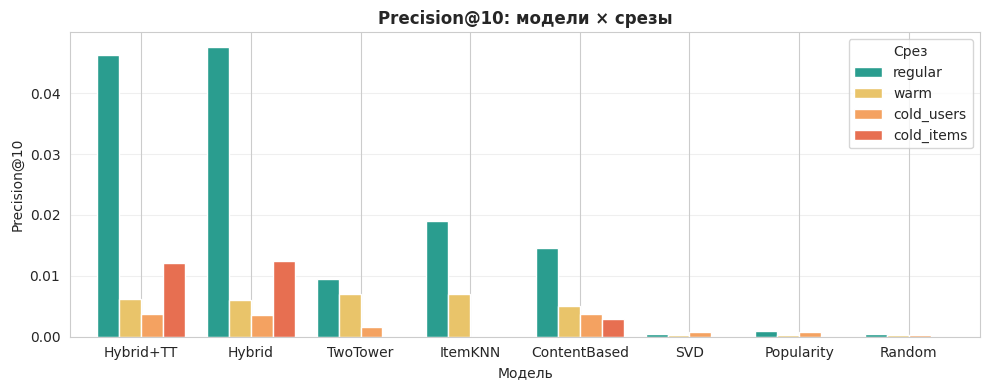

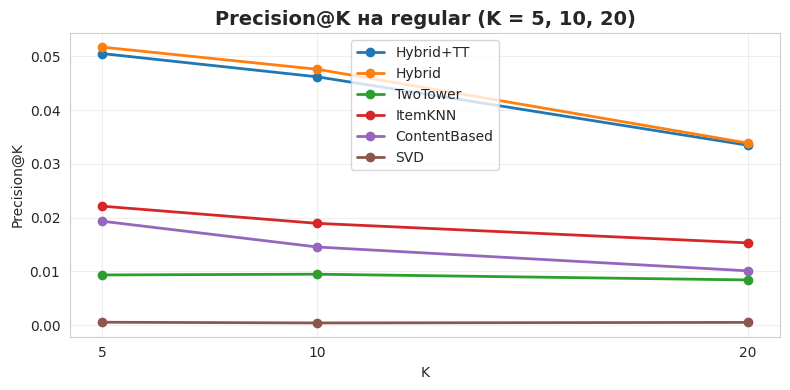

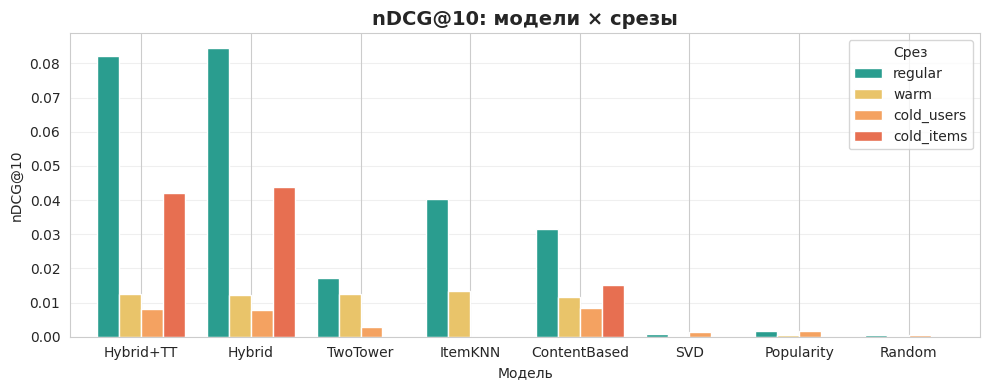

In [204]:
#Результаты:  8 моделей × 4 среза
os.makedirs(ARTIFACTS_DIR, exist_ok=True)
slice_order = ["regular", "warm", "cold_users", "cold_items"]
model_order = ["Hybrid+TT", "Hybrid", "TwoTower", "ItemKNN", "ContentBased",
               "SVD", "Popularity", "Random"]
slice_dfs = {
    "regular":    regular_df,
    "warm":       warm_df,
    "cold_users": cold_users_df,
    "cold_items": cold_items_df}
all_results = []
for slice_name, df in slice_dfs.items():
    for model_name in df.index:
        row = df.loc[model_name]
        all_results.append({
            "Slice": slice_name,
            "Model": model_name,
            "P@5":  row.get("Precision@5", np.nan),
            "P@10": row.get("Precision@10", np.nan),
            "P@20": row.get("Precision@20", np.nan),
            "R@5":  row.get("Recall@5", np.nan),
            "R@10": row.get("Recall@10", np.nan),
            "R@20": row.get("Recall@20", np.nan),
            "nDCG@5":  row.get("nDCG@5", np.nan),
            "nDCG@10": row.get("nDCG@10", np.nan),
            "nDCG@20": row.get("nDCG@20", np.nan),
            "Users": int(row.get("Users", 0)),
            "Time_s": float(row.get("Time", 0))})
all_results_df = pd.DataFrame(all_results)
model_order = [m for m in model_order if m in all_results_df["Model"].unique()]
print("СВОДНАЯ ТАБЛИЦА (8 моделей × 4 среза × 9 метрик)")
print(all_results_df.round(5).to_string(index=False))

#График: grouped bar P@10
p10_pivot = all_results_df.pivot(index="Model", columns="Slice", values="P@10")
p10_pivot = p10_pivot.reindex(model_order)[slice_order]
fig, ax = plt.subplots(figsize=(10, 4))
p10_pivot.plot(kind="bar", ax=ax, width=0.8,
               color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
ax.set_title("Precision@10: модели × срезы", fontsize=12, fontweight="bold")
ax.set_ylabel("Precision@10")
ax.set_xlabel("Модель")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Срез", loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#График: Precision@K на regular
fig, ax = plt.subplots(figsize=(8, 4))
regular_models = ["Hybrid+TT", "Hybrid", "TwoTower", "ItemKNN", "ContentBased", "SVD"]
regular_models = [m for m in regular_models if m in regular_df.index]
regular_pk = regular_df.loc[regular_models, ["Precision@5", "Precision@10", "Precision@20"]]
for model in regular_pk.index:
    ax.plot([5, 10, 20], regular_pk.loc[model].values,
            marker="o", label=model, linewidth=2)
ax.set_title("Precision@K на regular (K = 5, 10, 20)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("K")
ax.set_ylabel("Precision@K")
ax.set_xticks([5, 10, 20])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# График: grouped bar nDCG@10
ndcg_pivot = all_results_df.pivot(index="Model", columns="Slice", values="nDCG@10")
ndcg_pivot = ndcg_pivot.reindex(model_order)[slice_order]

fig, ax = plt.subplots(figsize=(10, 4))
ndcg_pivot.plot(kind="bar", ax=ax, width=0.8,
                color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
ax.set_title("nDCG@10: модели × срезы", fontsize=14, fontweight="bold")
ax.set_ylabel("nDCG@10")
ax.set_xlabel("Модель")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Срез", loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [216]:
#Финальная оценка на test_full
# Собираем test-срезы по тем же eval_users, чтобы метрики были сравнимы с val
test_regular    = test_full[test_full["user_id"].isin(eval_users_regular)].copy()
test_warm       = test_full[test_full["user_id"].isin(eval_users_warm)].copy()
test_cold_users = test_full[test_full["user_id"].isin(eval_users_cold)].copy()
test_cold_items = test_full[
    test_full["user_id"].isin(eval_users_cold_items) &
    test_full["book_id"].isin(hidden_books)].copy()
test_regular_fe    = add_rating_centered_inplace(attach_user_feats(test_regular,    user_feats_train))
test_warm_fe       = add_rating_centered_inplace(attach_user_feats(test_warm,       user_feats_train))
test_cold_users_fe = add_rating_centered_inplace(attach_user_feats(test_cold_users, user_feats_train))
test_cold_items_fe = add_rating_centered_inplace(attach_user_feats(test_cold_items, user_feats_train))
test_slices = {
    "regular":    (eval_users_regular,    test_regular_fe,    None),
    "warm":       (eval_users_warm,       test_warm_fe,       None),
    "cold_users": (eval_users_cold,       test_cold_users_fe, history_override_cold),
    "cold_items": (eval_users_cold_items, test_cold_items_fe, None)}

print("TEST METRICS (final_hybrid vs final_hybrid_tt)")
test_results = {}
for name, (users, df, hist) in test_slices.items():
    m_h  = evaluate(final_hybrid,    users, train_grouped_global, df,
                    K_LIST=(5,10,20), history_override=hist)
    m_ht = evaluate(final_hybrid_tt, users, train_grouped_global, df,
                    K_LIST=(5,10,20), history_override=hist)
    test_results[name] = {"Hybrid": m_h, "Hybrid+TT": m_ht}
    print(f"[{name:>10}] Hybrid: P@10={m_h['Precision@10']:.5f}, nDCG@10={m_h['nDCG@10']:.5f}")
    print(f"[{name:>10}] Hybrid+TT: P@10={m_ht['Precision@10']:.5f}, nDCG@10={m_ht['nDCG@10']:.5f}")

TEST METRICS (final_hybrid vs final_hybrid_tt)
[   regular] Hybrid: P@10=0.01783, nDCG@10=0.03173
[   regular] Hybrid+TT: P@10=0.01824, nDCG@10=0.03212
[      warm] Hybrid: P@10=0.00536, nDCG@10=0.01008
[      warm] Hybrid+TT: P@10=0.00569, nDCG@10=0.01045
[cold_users] Hybrid: P@10=0.00317, nDCG@10=0.00579
[cold_users] Hybrid+TT: P@10=0.00368, nDCG@10=0.00634
[cold_items] Hybrid: P@10=0.00455, nDCG@10=0.01669
[cold_items] Hybrid+TT: P@10=0.00498, nDCG@10=0.01775


## **Сквозной пайплайн**

Сквозной пайплайн рекомендаций книг
    
    Этапы:
      1. Загрузка данных
      2. Предобработка (очистка, TF-IDF)
      3. Leave-last-out split
      4. Пулы cold/warm + truncated_histories + hidden_books
      5. train_combined
      6. 4 среза val
      7. Признаки (temporal, user_feats, item_feats, rating_centered)
      8. Обучение гибрида (FinalHybridRec: ItemKNN + ContentBased + Popularity)
      9. Обучение TwoTower (опционально)
      10. Генерация рекомендаций (recommend)
      11. Оценка качества на 4 срезах  

Возвращает словарь с recommend, hybrid, hybrid_tt, metrics и metrics_tt на 4-х срезах.

In [217]:
del final_hybrid, final_hybrid_tt, models, regular_df, warm_df, cold_users_df, cold_items_df
del val_regular_fe, val_warm_fe, val_cold_users_fe, val_cold_items_fe
gc.collect()

30

In [218]:
#run_pipeline — гибрид (без TT)
def run_pipeline(data_dir="./goodbooks_data",
                 artifacts_dir="./artifacts",
                 random_state=42,
                 min_user_interactions=10,
                 n_synthetic_users=1000,
                 n_hidden_books=500,
                 min_history_for_others=3,
                 k_list=(5, 10, 20),
                 hybrid_params=None,
                 use_tt=False,
                 tt_params=None,
                 verbose=True):
    t_start = time.time()
    if verbose:
        print(f"run_pipeline: старт (random_state={random_state})")
    if hybrid_params is None:
        hybrid_params = dict(w_ibcf=0.7, w_content=0.3, w_pop=0.0,
                             content_top_k=1000, mmr_lambda=0.9)
    if tt_params is None:
        tt_params = dict(embed_dim=128, hidden_dim=256, tfidf_dim=64,
                         dropout=0.1, max_pos_per_user=3, n_epochs=15,
                         batch_size=8192, lr=1e-3, alpha_rc=0.1,
                         patience=3, min_delta=1e-4, w_tt=0.1)

     # Этап 1. Загрузка
    if verbose: print("[1/10] Загрузка данных...")
    os.makedirs(data_dir, exist_ok=True)
    os.makedirs(artifacts_dir, exist_ok=True)

    base_url = "https://github.com/zygmuntz/goodbooks-10k/releases/download/v1.0/"
    files_to_download = ["ratings.zip", "books.zip", "tags.zip", "book_tags.zip"]
    import urllib.request, zipfile
    for fname in files_to_download:
        zip_path = os.path.join(data_dir, fname)
        extract_marker = os.path.join(data_dir, fname.replace(".zip", ".csv"))
        if not os.path.exists(extract_marker):
            urllib.request.urlretrieve(base_url + fname, zip_path)
            with zipfile.ZipFile(zip_path, 'r') as z:
                z.extractall(data_dir)

    ratings   = pd.read_csv(os.path.join(data_dir, "ratings.csv"))
    books     = pd.read_csv(os.path.join(data_dir, "books.csv"))
    tags      = pd.read_csv(os.path.join(data_dir, "tags.csv"))
    book_tags = pd.read_csv(os.path.join(data_dir, "book_tags.csv"))

    # Этап 2. Предобработка
    if verbose: print("[2/10] Предобработка (очистка, TF-IDF)...")
    books_clean = books[["book_id", "title", "average_rating", "ratings_count"]].copy()
    if "original_order" not in ratings.columns:
        ratings = ratings.reset_index().rename(columns={"index": "original_order"})

    ratings_clean = (ratings
        .groupby(["user_id", "book_id"])
        .agg(rating=("rating", "mean"), original_order=("original_order", "min"))
        .reset_index())
    ratings_clean["is_relevant"] = (ratings_clean["rating"] >= 4).astype(int)
    book_tags_named = book_tags.merge(tags, on="tag_id", how="left")
    SERVICE_TAGS = {"to-read", "currently-reading", "read", "books-i-own", "owned", "owned-books",
                    "wish-list", "to-buy", "library", "ebook", "audiobook", "kindle", "paperback",
                    "hardcover", "favorites", "series", "book-club", "abandoned", "did-not-finish", "dnf"}
    book_tags_clean = book_tags_named[~book_tags_named["tag_name"].isin(SERVICE_TAGS)]
    book_id_map = books[["book_id", "goodreads_book_id"]].drop_duplicates(subset=["goodreads_book_id"], keep="first")
    book_tags_mapped = (book_tags_clean
        .merge(book_id_map, on="goodreads_book_id", how="left")
        .loc[:, ["book_id", "tag_name"]]
        .dropna(subset=["book_id"])
        .assign(book_id=lambda d: d["book_id"].astype(int))
        .copy())
    tags_per_book = (book_tags_mapped
        .groupby("book_id")["tag_name"]
        .apply(lambda s: " ".join(s.astype(str).str.replace("-", " ", regex=False)))
        .rename("tags_text")
        .reset_index())
    book_profiles = books_clean[["book_id", "title"]].merge(tags_per_book, on="book_id", how="left").fillna({"tags_text": ""})
    book_profiles["profile"] = (book_profiles["title"].fillna("") + " " + book_profiles["tags_text"]).str.strip()
    book_profiles.loc[book_profiles["profile"] == "", "profile"] = "unknown book"

    tfidf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
    tfidf_matrix = tfidf.fit_transform(book_profiles["profile"]).astype(np.float32)
    book_id_to_idx = {bid: i for i, bid in enumerate(book_profiles["book_id"])}

    TFIDF_TOP_K = 50
    tfidf_matrix_T = tfidf_matrix.T.tocsr()
    tfidf_top_neighbors = {}
    for bid, idx in book_id_to_idx.items():
        sims = (tfidf_matrix[idx] @ tfidf_matrix_T).toarray().ravel()
        sims[idx] = -np.inf
        top_idx = np.argpartition(-sims, TFIDF_TOP_K)[:TFIDF_TOP_K]
        top_idx = top_idx[np.argsort(-sims[top_idx])]
        tfidf_top_neighbors[bid] = (
            [int(book_profiles.iloc[i]["book_id"]) for i in top_idx],
            sims[top_idx].tolist())

    _titles_by_id_local = book_profiles.set_index("book_id")["title"].to_dict()

    def get_similar_books(book_id, N=5):
        if book_id not in tfidf_top_neighbors:
            return pd.DataFrame(columns=["book_id", "title", "similarity"])
        bids, sims = tfidf_top_neighbors[book_id]
        bids, sims = bids[:N], sims[:N]
        return pd.DataFrame({
            "book_id": bids,
            "title": [_titles_by_id_local.get(b, "") for b in bids],
            "similarity": sims})

    def get_user_top_genres(user_id, train_df, book_tags, top_n=5):
        user_books = train_df.loc[train_df["user_id"] == user_id, "book_id"].tolist()
        if not user_books:
            return []
        user_tags = book_tags.loc[book_tags["book_id"].isin(user_books), "tag_name"].tolist()
        if not user_tags:
            return []
        return [tag for tag, _ in Counter(user_tags).most_common(top_n)]

    # Этап 3. Leave-last-out split
    if verbose: print("[3/10] Leave-last-out split...")
    user_counts = ratings_clean.groupby("user_id").size()
    valid_users = user_counts[user_counts >= min_user_interactions].index
    ratings_filtered = ratings_clean[ratings_clean["user_id"].isin(valid_users)].copy()
    ratings_filtered = ratings_filtered.sort_values(["user_id", "original_order"]).reset_index(drop=True)
    ratings_filtered["rank"] = ratings_filtered.groupby("user_id").cumcount() + 1
    ratings_filtered["n_user"] = ratings_filtered.groupby("user_id")["rank"].transform("max")
    ratings_filtered["rank_from_end"] = ratings_filtered["n_user"] - ratings_filtered["rank"]

    train_full = ratings_filtered[ratings_filtered["rank_from_end"] >= 10].copy()
    val_full   = ratings_filtered[(ratings_filtered["rank_from_end"] >= 5) &
                                  (ratings_filtered["rank_from_end"] < 10)].copy()
    test_full  = ratings_filtered[ratings_filtered["rank_from_end"] < 5].copy()
    for df in (train_full, val_full, test_full):
        df.drop(columns=["rank", "n_user", "rank_from_end"], errors="ignore", inplace=True)

    # Этап 4. Пулы + truncated_histories + hidden_books
    if verbose: print("[4/10] Пулы cold/warm + hidden_books...")
    val_relevant = val_full[val_full["is_relevant"] == 1]
    eval_users_pool = sorted(val_relevant["user_id"].unique())
    train_user_counts = train_full.groupby("user_id").size().to_dict()
    active_users = [u for u in eval_users_pool if train_user_counts.get(u, 0) > 20]

    rng_pool = np.random.default_rng(random_state)
    active_shuffled = rng_pool.choice(active_users, size=min(2 * n_synthetic_users, len(active_users)), replace=False)
    cold_users_pool = set(active_shuffled[:n_synthetic_users])
    warm_users_pool = set(active_shuffled[n_synthetic_users:2 * n_synthetic_users])

    rng_trunc = np.random.default_rng(random_state + 1)
    truncated_histories = {}
    for uid in cold_users_pool:
        user_hist = train_full[train_full["user_id"] == uid].sort_values("original_order")
        if len(user_hist) == 0:
            truncated_histories[uid] = set()
            continue
        k = int(rng_trunc.integers(1, min(4, len(user_hist)) + 1))
        truncated_histories[uid] = set(user_hist.head(k)["book_id"])
    visible_cold_books = set().union(*truncated_histories.values()) if truncated_histories else set()

    rng_trunc_warm = np.random.default_rng(random_state + 3)
    truncated_histories_warm = {}
    for uid in warm_users_pool:
        user_hist = train_full[train_full["user_id"] == uid].sort_values("original_order")
        if len(user_hist) == 0:
            truncated_histories_warm[uid] = set()
            continue
        k = int(rng_trunc_warm.integers(5, min(20, len(user_hist)) + 1))
        truncated_histories_warm[uid] = set(user_hist.head(k)["book_id"])
    visible_warm_books = set().union(*truncated_histories_warm.values()) if truncated_histories_warm else set()

    val_books = set(val_full["book_id"].unique())
    candidate_books = sorted(val_books - visible_cold_books - visible_warm_books)
    hidden_books = set(rng_pool.choice(candidate_books, size=n_hidden_books, replace=False))

    # Этап 5. train_combined
    if verbose: print("[5/10] train_combined...")
    cold_users_set = set(truncated_histories.keys())
    warm_users_set = set(truncated_histories_warm.keys())
    other_part = train_full[
        (~train_full["user_id"].isin(cold_users_set)) &
        (~train_full["user_id"].isin(warm_users_set)) &
        (~train_full["book_id"].isin(hidden_books))].copy()
    cold_pairs = pd.DataFrame(
        [(uid, bid) for uid, books in truncated_histories.items() for bid in books],
        columns=["user_id", "book_id"], dtype=np.int64)
    cold_part = train_full[train_full["user_id"].isin(cold_users_set)
        ].merge(cold_pairs, on=["user_id", "book_id"], how="inner")
    cold_part = cold_part[~cold_part["book_id"].isin(hidden_books)].copy()
    warm_pairs = pd.DataFrame(
        [(uid, bid) for uid, books in truncated_histories_warm.items() for bid in books],
        columns=["user_id", "book_id"], dtype=np.int64)
    warm_part = train_full[train_full["user_id"].isin(warm_users_set)
        ].merge(warm_pairs, on=["user_id", "book_id"], how="inner")
    warm_part = warm_part[~warm_part["book_id"].isin(hidden_books)].copy()
    train_combined = pd.concat([other_part, cold_part, warm_part], ignore_index=True)
    del other_part, cold_part, warm_part
    gc.collect()
    counts = train_combined.groupby("user_id").size()
    keep_users = set(counts[counts >= min_history_for_others].index)
    train_combined = train_combined[train_combined["user_id"].isin(keep_users)].copy()

    # Этап 6. 4 среза val
    if verbose: print("[6/10] 4 среза val...")
    val_cold_items = val_full[val_full["book_id"].isin(hidden_books)].copy()
    cold_items_users = set(val_cold_items[val_cold_items["is_relevant"] == 1]["user_id"].unique())
    cold_users_set_eval = set(cold_users_pool) & set(eval_users_pool)
    cold_items_set = cold_items_users - cold_users_set_eval
    warm_users_set_eval = (set(warm_users_pool) & set(eval_users_pool)
                           - cold_users_set_eval - cold_items_set)
    regular_set = (set(eval_users_pool) - cold_users_set_eval - cold_items_set - warm_users_set_eval)
    rng_eval = np.random.default_rng(random_state + 2)
    if len(regular_set) > 1500:
        regular_list = sorted(regular_set)
        pick = rng_eval.choice(len(regular_list), size=1500, replace=False)
        regular_set = {regular_list[i] for i in sorted(pick)}

    eval_users_regular    = sorted(regular_set)
    eval_users_cold       = sorted(cold_users_set_eval)
    eval_users_cold_items = sorted(cold_items_set)
    eval_users_warm       = sorted(warm_users_set_eval)

    val_regular    = val_full[val_full["user_id"].isin(eval_users_regular)].copy()
    val_cold_users = val_full[val_full["user_id"].isin(eval_users_cold)].copy()
    val_cold_items = val_full[val_full["user_id"].isin(eval_users_cold_items) &
                              val_full["book_id"].isin(hidden_books)].copy()
    val_warm = val_full[val_full["user_id"].isin(eval_users_warm)].copy()
    history_override_cold = {uid: truncated_histories.get(uid, set()) for uid in eval_users_cold}

    # Этап 7. Признаки
    if verbose: print("[7/10] Признаки...")
    def add_temporal_features(df):
        df = df.sort_values(["user_id", "original_order"]).reset_index(drop=True)
        df["rank"] = df.groupby("user_id").cumcount() + 1
        df["n_user"] = df.groupby("user_id")["rank"].transform("max")
        df["rank_from_end"] = df["n_user"] - df["rank"]
        df["recency_weight"] = np.exp(-df["rank_from_end"] / 5.0)
        return df

    train_combined_t = add_temporal_features(train_combined)
    user_avg_rating_map = train_combined_t.groupby("user_id")["rating"].mean()
    train_combined_t["user_avg_rating"] = train_combined_t["user_id"].map(user_avg_rating_map)
    train_combined_t["rating_centered"] = train_combined_t["rating"] - train_combined_t["user_avg_rating"]

    user_feats_train = (train_combined_t.groupby("user_id")
        .agg(user_n_ratings=("rating", "size"),
             user_avg_rating=("rating", "mean"),
             user_std_rating=("rating", "std")).reset_index())
    user_feats_train["user_std_rating"] = user_feats_train["user_std_rating"].fillna(0)
    user_feats_train["user_log_n_ratings"] = np.log1p(user_feats_train["user_n_ratings"])

    high_rated = train_combined_t[train_combined_t["rating"] >= 4].copy()
    high_rated["history_position"] = high_rated["rank"] / high_rated["n_user"]
    agg_temporal = (high_rated.groupby("user_id")
        .agg(user_avg_history_position=("history_position", "mean"),
             user_recency_bias=("recency_weight", "mean")).reset_index())
    user_feats_train = user_feats_train.merge(agg_temporal, on="user_id", how="left")
    user_feats_train["user_avg_history_position"] = user_feats_train["user_avg_history_position"].fillna(0.5)
    user_feats_train["user_recency_bias"] = user_feats_train["user_recency_bias"].fillna(0.0)

    agg_user_rc = (high_rated.groupby("user_id")
        .agg(user_avg_rating_centered=("rating_centered", "mean")).reset_index())
    user_feats_train = user_feats_train.merge(agg_user_rc, on="user_id", how="left")
    user_feats_train["user_avg_rating_centered"] = user_feats_train["user_avg_rating_centered"].fillna(0.0)

    item_feats_train = (train_combined_t.groupby("book_id")
        .agg(item_n_ratings=("rating", "size"),
             item_avg_rating=("rating", "mean"),
             item_std_rating=("rating", "std")).reset_index())
    item_feats_train["item_std_rating"] = item_feats_train["item_std_rating"].fillna(0)
    item_feats_train["item_log_n_ratings"] = np.log1p(item_feats_train["item_n_ratings"])
    agg_item_rc = (train_combined_t.groupby("book_id")
        .agg(item_avg_rating_centered=("rating_centered", "mean")).reset_index())
    item_feats_train = item_feats_train.merge(agg_item_rc, on="book_id", how="left")
    item_feats_train["item_avg_rating_centered"] = item_feats_train["item_avg_rating_centered"].fillna(0.0)

    USER_FEAT_COLS = ["user_n_ratings", "user_avg_rating", "user_std_rating",
                      "user_log_n_ratings", "user_avg_history_position",
                      "user_recency_bias", "user_avg_rating_centered"]
    def attach_user_feats(df, user_feats):
        out = df.merge(user_feats[["user_id"] + USER_FEAT_COLS], on="user_id", how="left", validate="many_to_one")
        out["user_n_ratings"] = out["user_n_ratings"].fillna(0).astype(int)
        out["user_log_n_ratings"] = out["user_log_n_ratings"].fillna(0.0)
        out["user_avg_rating"] = out["user_avg_rating"].fillna(user_feats["user_avg_rating"].mean())
        out["user_std_rating"] = out["user_std_rating"].fillna(0.0)
        out["user_avg_history_position"] = out["user_avg_history_position"].fillna(0.5)
        out["user_recency_bias"] = out["user_recency_bias"].fillna(0.0)
        out["user_avg_rating_centered"] = out["user_avg_rating_centered"].fillna(0.0)
        return out

    val_regular_fe    = attach_user_feats(val_regular,    user_feats_train)
    val_cold_users_fe = attach_user_feats(val_cold_users, user_feats_train)
    val_cold_items_fe = attach_user_feats(val_cold_items, user_feats_train)
    val_warm_fe       = attach_user_feats(val_warm,       user_feats_train)
    train_grouped_global = (train_combined_t.groupby("user_id")["book_id"].apply(set).to_dict())


    # Этап 8. Обучение гибрида (внутри — ItemKNN + ContentBased + Popularity)
    if verbose: print("[8/10] Обучение гибрида...")
    all_users = sorted(train_combined_t["user_id"].unique())
    all_books_arr = sorted(train_combined_t["book_id"].unique())
    u2i = {uid: i for i, uid in enumerate(all_users)}
    i2i = {bid: i for i, bid in enumerate(all_books_arr)}
    i2b = {i: bid for bid, i in i2i.items()}
    n_users = len(all_users)
    n_books = len(all_books_arr)

    from scipy.sparse import csr_matrix
    rows = train_combined_t["user_id"].map(u2i).values
    cols = train_combined_t["book_id"].map(i2i).values
    vals = train_combined_t["rating"].values.astype(np.float32)
    M_combined = csr_matrix((vals, (rows, cols)), shape=(n_users, n_books))

    ibcf = ItemKNN(k=100).fit(M_combined, batch_size=500)
    ibcf_wrapper = ItemKNNRec(ibcf, u2i, i2i, i2b, min_history=5)
    pop_model = PopularityRec(min_ratings=30).fit(train_combined_t)
    content_model = ContentBasedRec(
        get_similar_fn=get_similar_books,
        train_df=train_combined_t,
        book_tags=book_tags_mapped,
        n_seed_books=5, genre_bonus=0.5)

    hybrid = FinalHybridRec(
        popularity_model=pop_model,
        content_model=content_model,
        ibcf_model=ibcf_wrapper,
        train_df=train_combined_t,
        book_id_to_idx=book_id_to_idx,
        tfidf_matrix=tfidf_matrix,
        tfidf_matrix_T=tfidf_matrix_T,
        train_grouped=train_grouped_global,
        user_feats=user_feats_train,
        item_feats=item_feats_train,
        min_history=5,
        **hybrid_params)


    #Этап 8.1 Two-Tower (опционально)
    final_hybrid_tt = None
    if use_tt:
        if verbose: print("[8.5/10] Two-Tower...")
        DEVICE_ = "cuda" if torch.cuda.is_available() else "cpu"
        # маппинги TT
        user_ids_tt = sorted(train_combined_t["user_id"].unique())
        book_ids_tt = sorted(train_combined_t["book_id"].unique())
        u2i_tt = {uid: i for i, uid in enumerate(user_ids_tt)}
        i2i_tt = {bid: i for i, bid in enumerate(book_ids_tt)}
        i2b_tt = {i: bid for bid, i in i2i_tt.items()}
        n_users_tt, n_books_tt = len(user_ids_tt), len(book_ids_tt)
        user_feat_cols = ["user_n_ratings", "user_avg_rating", "user_std_rating",
                          "user_log_n_ratings", "user_avg_history_position",
                          "user_recency_bias", "user_avg_rating_centered"]
        item_feat_cols = ["item_n_ratings", "item_avg_rating", "item_std_rating",
                          "item_log_n_ratings", "item_avg_rating_centered"]
        user_feats_tt = (user_feats_train.set_index("user_id")[user_feat_cols]
                         .reindex(user_ids_tt).fillna(0.0).values.astype(np.float32))
        item_feats_tt = (item_feats_train.set_index("book_id")[item_feat_cols]
                         .reindex(book_ids_tt).fillna(0.0).values.astype(np.float32))
        # TF-IDF -> SVD
        svd_tt = TruncatedSVD(n_components=tt_params["tfidf_dim"], random_state=random_state)
        tfidf_proj = svd_tt.fit_transform(tfidf_matrix)
        tfidf_proj_full = np.zeros((n_books_tt, tt_params["tfidf_dim"]), dtype=np.float32)
        for i, bid in enumerate(book_ids_tt):
            if bid in book_id_to_idx:
                tfidf_proj_full[i] = tfidf_proj[book_id_to_idx[bid]]
        user_scaler = StandardScaler(); item_scaler = StandardScaler()
        user_feats_tt = user_scaler.fit_transform(user_feats_tt).astype(np.float32)
        item_feats_tt = item_scaler.fit_transform(item_feats_tt).astype(np.float32)

        # модель
        torch.manual_seed(random_state); np.random.seed(random_state); random.seed(random_state)
        tt_model = TwoTower(
            n_users=n_users_tt, n_books=n_books_tt,
            user_feat_dim=user_feats_tt.shape[1],
            item_feat_dim=item_feats_tt.shape[1],
            tfidf_dim=tt_params["tfidf_dim"],
            embed_dim=tt_params["embed_dim"],
            hidden_dim=tt_params["hidden_dim"],
            dropout=tt_params["dropout"]).to(DEVICE_)

        # пары + негативы
        train_pairs_tt = train_combined_t[["user_id", "book_id", "rating_centered"]].copy()
        train_pairs_tt["user_idx"] = train_pairs_tt["user_id"].map(u2i_tt)
        train_pairs_tt["book_idx"] = train_pairs_tt["book_id"].map(i2i_tt)
        train_pairs_tt = train_pairs_tt.dropna(subset=["user_idx", "book_idx"])
        train_pairs_tt["user_idx"] = train_pairs_tt["user_idx"].astype(int)
        train_pairs_tt["book_idx"] = train_pairs_tt["book_idx"].astype(int)

        MAX_POS = tt_params["max_pos_per_user"]
        positives = (train_pairs_tt.groupby("user_id", group_keys=False)
                     .apply(lambda g: g.sample(min(len(g), MAX_POS), random_state=random_state))
                     .reset_index(drop=True))
        user_pos = positives.groupby("user_id")["book_id"].apply(set).to_dict()
        rng_neg = np.random.default_rng(random_state)
        neg_rows = []
        for _, row in positives.iterrows():
            uid = row["user_id"]; pos_set = user_pos[uid]
            for _ in range(5):
                for _try in range(10):
                    bid = int(rng_neg.choice(book_ids_tt))
                    if bid not in pos_set:
                        neg_rows.append({"user_id": uid, "book_id": bid, "rating_centered": 0.0})
                        break
        negatives = pd.DataFrame(neg_rows)
        positives["target"] = 1; negatives["target"] = 0
        train_tt = pd.concat([positives, negatives], ignore_index=True)
        train_tt["user_idx"] = train_tt["user_id"].map(u2i_tt)
        train_tt["book_idx"] = train_tt["book_id"].map(i2i_tt)
        train_tt = train_tt.dropna(subset=["user_idx", "book_idx"]).reset_index(drop=True)

        # val-пары
        val_pos = val_regular_fe[["user_id", "book_id", "rating_centered"]].copy()
        val_pos["target"] = 1
        val_user_pos = val_regular_fe.groupby("user_id")["book_id"].apply(set).to_dict()
        val_neg_rows = []
        for uid, pos_set in val_user_pos.items():
            for _ in range(10):
                for _try in range(10):
                    bid = int(rng_neg.choice(book_ids_tt))
                    if bid not in pos_set:
                        val_neg_rows.append({"user_id": uid, "book_id": bid,
                                             "rating_centered": 0.0, "target": 0})
                        break
        val_tt = pd.concat([val_pos, pd.DataFrame(val_neg_rows)], ignore_index=True)
        val_tt["user_idx"] = val_tt["user_id"].map(u2i_tt)
        val_tt["book_idx"] = val_tt["book_id"].map(i2i_tt)
        val_tt = val_tt.dropna(subset=["user_idx", "book_idx"]).reset_index(drop=True)

        # чистка
        del train_pairs_tt, positives, negatives, val_pos, val_neg_rows, neg_rows, user_pos, val_user_pos
        gc.collect()

        # тензоры
        user_feats_t = torch.from_numpy(user_feats_tt).to(DEVICE_)
        item_feats_t = torch.from_numpy(item_feats_tt).to(DEVICE_)
        tfidf_proj_t = torch.from_numpy(tfidf_proj_full).to(DEVICE_)

        # обучение
        ALPHA_RC = tt_params["alpha_rc"]
        optimizer = optim.Adam(tt_model.parameters(), lr=tt_params["lr"])
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.3, patience=3, min_lr=1e-7)
        criterion = nn.BCEWithLogitsLoss()
        es = EarlyStopping(patience=tt_params["patience"],
                           min_delta=tt_params["min_delta"])
        batch_size = tt_params["batch_size"]
        for epoch in range(tt_params["n_epochs"]):
            tt_model.train()
            perm = rng_neg.permutation(len(train_tt))
            total_loss, n_batches = 0.0, 0
            for start in range(0, len(perm), batch_size):
                end = min(start + batch_size, len(perm))
                batch = train_tt.iloc[perm[start:end]]
                u_b  = torch.tensor(batch["user_idx"].values, dtype=torch.long, device=DEVICE_)
                i_b  = torch.tensor(batch["book_idx"].values, dtype=torch.long, device=DEVICE_)
                y_b  = torch.tensor(batch["target"].values, dtype=torch.float32, device=DEVICE_)
                rc_b = torch.tensor(batch["rating_centered"].values, dtype=torch.float32, device=DEVICE_)
                logits = tt_model(u_b, i_b, user_feats_t[u_b], item_feats_t[i_b],
                                  tfidf_proj_t[i_b], rating_centered=rc_b, alpha=ALPHA_RC)
                loss = criterion(logits, y_b)
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                total_loss += loss.item(); n_batches += 1
            train_loss = total_loss / max(n_batches, 1)
            tt_model.eval()
            with torch.no_grad():
                u_v  = torch.tensor(val_tt["user_idx"].values, dtype=torch.long, device=DEVICE_)
                i_v  = torch.tensor(val_tt["book_idx"].values, dtype=torch.long, device=DEVICE_)
                y_v  = torch.tensor(val_tt["target"].values, dtype=torch.float32, device=DEVICE_)
                rc_v = torch.tensor(val_tt["rating_centered"].values, dtype=torch.float32, device=DEVICE_)
                val_logits = tt_model(u_v, i_v, user_feats_t[u_v], item_feats_t[i_v],
                                      tfidf_proj_t[i_v], rating_centered=rc_v, alpha=ALPHA_RC)
                val_loss = criterion(val_logits, y_v).item()
            if verbose:
                print(f"  TT epoch {epoch+1}/{tt_params['n_epochs']} | "
                      f"train={train_loss:.4f} | val={val_loss:.4f}")

            scheduler.step(val_loss)
            if es(val_loss, tt_model):
                if verbose: print(f"  TT early stopping на эпохе {epoch+1}")
                break
        es.load_best(tt_model)

        # item_vecs
        tt_model.eval()
        with torch.no_grad():
            all_book_ids_t = torch.arange(n_books_tt, dtype=torch.long, device=DEVICE_)
            item_vecs = tt_model.get_item_vec(
                all_book_ids_t, item_feats_t, tfidf_proj_t).cpu().numpy()

        user_avg_rc_map = dict(zip(user_feats_train["user_id"],
                                   user_feats_train["user_avg_rating_centered"]))

        # FinalHybridWithTT
        final_hybrid_tt = FinalHybridWithTT(
            tt_item_vecs=item_vecs, tt_u2i=u2i_tt,
            tt_user_feats_t=user_feats_t, tt_model=tt_model,
            user_avg_rc_map=user_avg_rc_map, w_tt=tt_params["w_tt"],
            popularity_model=pop_model, content_model=content_model,
            ibcf_model=ibcf_wrapper, train_df=train_combined_t,
            book_id_to_idx=book_id_to_idx,
            tfidf_matrix=tfidf_matrix, tfidf_matrix_T=tfidf_matrix_T,
            train_grouped=train_grouped_global,
            user_feats=user_feats_train, item_feats=item_feats_train,
            min_history=5, **hybrid_params)
        # чистка
        del train_tt, val_tt, user_feats_t, item_feats_t, tfidf_proj_t
        gc.collect()


    # Этап 9. Оценка гибрида на 4 срезах
    if verbose: print("[9/10] Оценка гибрида на 4 срезах...")
    slice_configs = [
        ("regular",    eval_users_regular,    val_regular_fe,    None),
        ("warm",       eval_users_warm,       val_warm_fe,       None),
        ("cold_users", eval_users_cold,       val_cold_users_fe, history_override_cold),
        ("cold_items", eval_users_cold_items, val_cold_items_fe, None)]

    metrics_results = {}
    metrics_tt_results = {}
    for slice_name, eval_users, eval_df, hist_override in slice_configs:
        m = evaluate(hybrid, eval_users, train_grouped_global, eval_df,
                     K_LIST=k_list, history_override=hist_override)
        metrics_results[slice_name] = m
        if verbose:
            print(f"  [{slice_name}] Hybrid: "
                  f"P@10={m['Precision@10']:.5f}, nDCG@10={m['nDCG@10']:.5f}")

        if final_hybrid_tt is not None:
            m_tt = evaluate(final_hybrid_tt, eval_users, train_grouped_global, eval_df,
                            K_LIST=k_list, history_override=hist_override)
            metrics_tt_results[slice_name] = m_tt
            if verbose:
                print(f"  [{slice_name}] Hybrid+TT: "
                      f"P@10={m_tt['Precision@10']:.5f}, nDCG@10={m_tt['nDCG@10']:.5f}")

    # Этап 10. Функция recommend()
    if verbose: print("[10/10] Функция recommend()...")
    titles_map = book_profiles.set_index("book_id")["title"].to_dict()

    def recommend(user_id, N=10, return_titles=False):
        history = set(train_combined_t.loc[
            train_combined_t["user_id"] == user_id, "book_id"])
        recs = hybrid.recommend(user_id, N=N, history=history)
        if not recs:
            recs = pop_model.recommend(user_id, N=N, history=history)
        if return_titles:
            return [{"book_id": bid, "title": titles_map.get(bid, "")} for bid in recs]
        return recs

    results = {
        "train_combined": train_combined_t,
        "val_slices": {
            "regular":    (eval_users_regular,    val_regular_fe),
            "warm":       (eval_users_warm,       val_warm_fe),
            "cold_users": (eval_users_cold,       val_cold_users_fe, history_override_cold),
            "cold_items": (eval_users_cold_items, val_cold_items_fe)},
        "hybrid": hybrid,
        "hybrid_components": {
            "itemknn": ibcf_wrapper,
            "content": content_model,
            "popularity": pop_model},
        "user_feats": user_feats_train,
        "item_feats": item_feats_train,
        "book_id_to_idx": book_id_to_idx,
        "tfidf_matrix": tfidf_matrix,
        "tfidf_matrix_T": tfidf_matrix_T,
        "tfidf_top_neighbors": tfidf_top_neighbors,
        "train_grouped": train_grouped_global,
        "u2i": u2i, "i2i": i2i, "i2b": i2b,
        "hybrid_tt": final_hybrid_tt,
        "metrics": metrics_results,
        "metrics_tt": metrics_tt_results,
        "recommend": recommend,
        "elapsed": time.time() - t_start}

    if verbose:
        print(f"  train_combined: {len(train_combined_t):,}")
        print(f"  гибрид: FinalHybridRec (ItemKNN + ContentBased + Popularity)")
        print(f"  метрики:")
        for slice_name, m in metrics_results.items():
            print(f"    {slice_name:<12} Hybrid P@10={m['Precision@10']:.5f}")
        if metrics_tt_results:
            for slice_name, m in metrics_tt_results.items():
                print(f"    {slice_name:<12} Hybrid+TT P@10={m['Precision@10']:.5f}")
        sample_uid = int(train_combined_t["user_id"].iloc[0])
        sample_recs = results["recommend"](sample_uid, N=5, return_titles=True)
        print(f"\nПример рекомендаций для user_id={sample_uid}:")
        for r in sample_recs:
            print(f"  book_id={r['book_id']}, title={r['title']}")

    return results

print(" run_pipeline определён")

 run_pipeline определён


In [219]:
#пайплайн: реальные рекомендации для 4 срезов
BOOK_LINE = "📚" + "─" * 20 + "📖" + "─" * 20 + "📚"

if "res" not in dir():
    res = run_pipeline(
        data_dir="./goodbooks_data",
        artifacts_dir="./artifacts",
        random_state=42,
        min_user_interactions=10,
        n_synthetic_users=100,
        n_hidden_books=50,
        use_tt=False,
        min_history_for_others=3,
        k_list=(5, 10, 20),
        hybrid_params=dict(
            w_ibcf=0.7, w_content=0.3, w_pop=0.0,
            content_top_k=1000, mmr_lambda=0.9),
        verbose=False)

try:
    _titles = book_profiles.set_index("book_id")["title"].to_dict()
except NameError:
    _titles = {}

def _print_recs(header, recs, titles=None):
    print("\n" + BOOK_LINE)
    print(header)
    for i, r in enumerate(recs, 1):
        if isinstance(r, dict):
            bid   = r["book_id"]
            title = r.get("title") or (titles or {}).get(bid, "")
        else:
            bid   = r
            title = (titles or {}).get(bid, "")
        print(f"  {i:>2}. book_id={bid:<6} | {str(title)[:70] or '(без названия)'}")

print("📚 ГИБРИДНАЯ РЕКОМЕНДАТЕЛЬНАЯ СИСТЕМА: ФИНАЛЬНЫЕ РЕКОМЕНДАЦИИ")
print(f"Пайплайн: {res['elapsed']:.1f}s | train_combined: {len(res['train_combined']):,} строк")

for name in ("regular", "warm", "cold_users", "cold_items"):
    users = res["val_slices"][name][0]
    if len(users) == 0:
        print(f"\n{BOOK_LINE}")
        print(f"[{name}] — нет пользователей в smoke-режиме, пропуск")
        print(BOOK_LINE)
        continue
    uid  = int(users[0])
    hist = res["train_grouped"].get(uid, set())
    recs = res["recommend"](uid, N=10, return_titles=True)
    _print_recs(f"[{name}]  user_id={uid} | история: {len(hist)} книг", recs)


print("\n" + "📚" + "─" * 20 + "📖" + "─" * 20 + "📚")

📚 ГИБРИДНАЯ РЕКОМЕНДАТЕЛЬНАЯ СИСТЕМА: ФИНАЛЬНЫЕ РЕКОМЕНДАЦИИ
Пайплайн: 139.5s | train_combined: 5,401,425 строк

📚────────────────────📖────────────────────📚
[regular]  user_id=72 | история: 99 книг
   1. book_id=11     | The Kite Runner
   2. book_id=5      | The Great Gatsby
   3. book_id=31     | The Help
   4. book_id=2      | Harry Potter and the Sorcerer's Stone (Harry Potter, #1)
   5. book_id=634    | I've Got Your Number
   6. book_id=1923   | Barrel Fever: Stories and Essays
   7. book_id=2581   | Mini Shopaholic (Shopaholic, #6)
   8. book_id=6300   | Sleeping Arrangements
   9. book_id=761    | Twenties Girl
  10. book_id=605    | Are You There, Vodka? It's Me, Chelsea

📚────────────────────📖────────────────────📚
[warm]  user_id=399 | история: 20 книг
   1. book_id=4      | To Kill a Mockingbird
   2. book_id=5      | The Great Gatsby
   3. book_id=8      | The Catcher in the Rye
   4. book_id=11     | The Kite Runner
   5. book_id=45     | Life of Pi
   6. book_id=28     | 

## Выводы:

В качестве финальной модели выбрана Hybrid+TT (w_tt=0.1), поскольку при оценке на тестовой выборке она превосходит Hybrid на всех четырёх срезах. В частности, на сегменте regular одно попадание приходится примерно на 5.5 выдач, тогда как у Hybrid на 5.6; а на сегменте cold_users 27 против 32; на сегменте cold_items  20 против 22. Таким образом, нейросетевая часть придаёт модели дополнительную обобщающую способность, которая не проявляется на валидационной выборке из-за близости к baseline, однако становится заметной на отложенных данных.

Hybrid без нейросетевой части остаётся сильной базовой моделью. На валидационной выборке он демонстрирует лучший результат среди одиночных моделей: на сегменте regular одно попадание приходится примерно на 2.1 выдачи, на сегменте cold_items на 8. При этом на валидационной выборке Hybrid+TT лишь незначительно уступает Hybrid. На сегменте regular среднее число релевантных книг в топ-10 составляет 0.48, тогда как у Hybrid 0.46; на сегменте cold_items 0.12 против 0.13 (разница в пределах шума). Следовательно, на валидационной выборке обе модели эквивалентны, тогда как на тестовой Hybrid+TT оказывается лучше, что и служит решающим аргументом в пользу выбора Hybrid+TT в качестве финальной модели.

Hybrid+TT дополняет стратегию гибрида (Popularity, ContentBased и взвешенный blend ItemKNN+Content+Pop+MMR) нейросетевым сигналом, который не ухудшает качество и повышает устойчивость на отложенных данных.

Отдельная модель TwoTower уступает классическим подходам на всех сегментах, кроме warm, где она находится на уровне лучших. TwoTower не способна рекомендовать книги, отсутствующие в её каталоге, и недостаточно хорошо ранжирует top-N на разреженных данных при использовании BCE-loss. Тем не менее, в качестве дополнительного источника кандидатов она оказывается полезной, что и используется в Hybrid+TT.

Анализ по сегментам показывает неоднородность: на сегменте regular лучшей на тестовой выборке оказывается Hybrid+TT, на сегменте warm различия между ItemKNN, TwoTower и Hybrid+TT несущественны, на сегменте cold_users на валидационной выборке лучшей является ContentBased, однако на тестовой выборке Hybrid+TT её обгоняет, а на сегменте cold_items лучшей на тестовой выборке оказывается Hybrid+TT. Таким образом, единой модели, превосходящей остальные на всех сегментах, не существует, однако Hybrid+TT демонстрирует наибольшую стабильность, поскольку на каждом из сегментов она либо лидирует, либо находится в пределах статистического шума.

SVD и Popularity непригодны в качестве top-N ранжировщиков. SVD фактически находится на уровне Random (одно попадание примерно на 15 000 выдач), поскольку оптимизирует RMSE рейтинга, а не порядок рекомендаций. Popularity уступает Random из-за сортировки по avg_rating без учёта n_ratings.

Сегмент cold_items оказывается наиболее сложным. У лучшей модели Hybrid+TT на тестовой выборке одно попадание приходится примерно на 20 выдач, тогда как на сегменте regular на 5.5; все коллаборативные модели и TwoTower на этом сегменте показывают строго нулевые значения. Работает исключительно контентный сигнал (TF-IDF по title и tags), которого достаточно для попадания в top-20 (одно попадание примерно на 5 по Recall@20), но недостаточно для попадания в top-10.

Сквозной пайплайн реализует два сценария: Hybrid в качестве базовой модели и Hybrid+TT в качестве финальной. Оба сценария воспроизводимы через run_pipeline при значении use_tt=False или use_tt=True соответственно.

В целом абсолютные значения метрик находятся на низком или среднем уровне, чтобы использовать полученную модель как самостоятельный production-ранкер, но можно использовать как первый фильстр кандидатов. Для использования как самостоятельного решения требуются дальнейшие улучшения системы.


**Рекомендации по улучшению**

1) Улучшение Two-Tower за счёт смены парадигмы обучения и последовательностной архитектуры. Замена на listwise-loss + hard-negatives из ItemKNN, и dot-product TT на SASRec/BERT4Rec, который видит историю как последовательность, ожидается, что превратит TT в ранкер. Это требует больше памяти и времени на обучение.

2) Улучшение качества контента за счёт внешних текстовых эмбеддингов. Сейчас TF-IDF по title+tags единственный сигнал для cold_items. Но его можно улучшить, подключив Google Books API в BERT-эмбеддинги описаний.

3) Улучшение user-item представлений за счёт графовой модели. GNN (LightGCN/PinSage) на графе «юзер–книга» использует multi-hop соседство (то, чего нет ни у ItemKNN, ни у TT).

